# Prediksi Cicilan dan Kemampuan Finansial Pembelian Mobil
### Analisis data, perbandingan model, optimasi, dan validasi

**Tujuan:** memperkirakan nominal cicilan bulanan dan mengklasifikasikan kemampuan bayar berdasarkan rasio cicilan maksimum 35% dari penghasilan. Label merupakan aturan simulasi, bukan keputusan persetujuan kredit aktual.

Notebook membandingkan 7 algoritma regresi dan 6 klasifikasi dalam tiga skenario: fitur asli, fitur asli dengan tuning, serta fitur finansial dengan tuning. Random Forest, Decision Tree dan XGBoost tetap menjadi kandidat. Rumus finansial dan aturan 35% adalah baseline non-ML.

 Hasil ekspor berada di `outputs_car_financing/`. Dataset mentah tidak diubah maupun diekspor.

In [ ]:
%pip install pandas numpy matplotlib seaborn scikit-learn xgboost joblib

## 1. Import dan konfigurasi
Seed tetap untuk reproduksibilitas. Pencarian parameter memakai sampel development yang sama agar biaya komputasi terkendali; model terpilih dilatih ulang pada seluruh development set. Lima fold dipakai untuk seleksi, final test tidak dipakai dalam tuning. Dataset telah diperiksa pada audit sebelumnya sehingga final test adalah holdout internal, bukan validasi eksternal independen.

In [ ]:
import os, json, sys, time, hashlib, platform, importlib.metadata as im
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, GradientBoostingRegressor, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold, GroupShuffleSplit,
    cross_validate, RandomizedSearchCV, learning_curve)
from sklearn.metrics import (mean_absolute_error, median_absolute_error, mean_squared_error, r2_score,
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, average_precision_score,
    RocCurveDisplay, PrecisionRecallDisplay, make_scorer)
from xgboost import XGBRegressor, XGBClassifier

SEED = 2026
THRESHOLD = 0.35
N_FOLDS = 5
SEARCH_ROWS = 12000
N_ITER = 4
N_JOBS = min(2, os.cpu_count() or 1)
DATA_PATH = Path('indonesia_car_sales_bigdata.csv')
OUT = Path('outputs_car_financing')
OUT.mkdir(exist_ok=True)
FIG = OUT / 'figures'
FIG.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
versions = {p: im.version(p) for p in ['numpy','pandas','scikit-learn','xgboost','joblib','matplotlib','seaborn']}
print('Python:', platform.python_version(), '| Library:', versions)

def showfig(name):
    plt.tight_layout()
    plt.savefig(FIG / (name + '.png'), dpi=140, bbox_inches='tight')
    plt.show()
    plt.close()

Python: 3.13.18 | Library: {'numpy': '2.4.6', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'xgboost': '3.4.1', 'joblib': '1.6.0', 'matplotlib': '3.10.0', 'seaborn': '0.13.2'}


## 2. Data profiling dan kualitas data
Identitas/kontak tidak ditampilkan. Missing pada kolom yang tidak digunakan bukan alasan membuang transaksi. Duplikasi penuh dan duplikasi ID diperiksa sebelum seleksi fitur; kemiripan nilai finansial bukan otomatis transaksi duplikat.

,dtype,missing,missing_pct,unique
Car_id,object,0,0.0000,100000
Date,object,0,0.0000,731
Customer Name,object,0,0.0000,86798
Gender,object,0,0.0000,2
Customer_Age,int64,0,0.0000,45
Marital_Status,object,0,0.0000,3
Education_Level,object,0,0.0000,5
Annual Income,int64,0,0.0000,99985
Occupation,object,0,0.0000,15
Province,object,0,0.0000,14


Dimensi: (100000, 36) | Duplikat penuh: 0 | ID berulang: 0


,jumlah
Payment_Method,
Credit,75020
Cash,24980


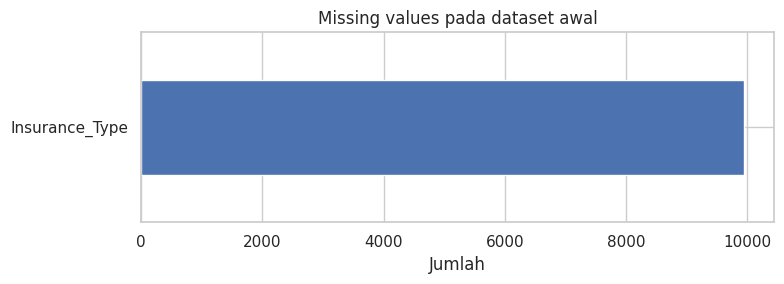

In [ ]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(f'Letakkan dataset di {DATA_PATH.resolve()}')
raw = pd.read_csv(DATA_PATH)
source_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
rename = {'Date':'date','Company':'company','Model':'model','Body Style':'body_style',
          'Engine':'engine','Transmission':'transmission','Price (IDR)':'price_idr',
          'Annual Income':'annual_income','Down_Payment':'down_payment',
          'Loan_Tenure':'loan_tenure','Monthly_Installment':'monthly_installment'}
required = set(rename) | {'Payment_Method','Car_id'}
assert required.issubset(raw.columns), f'Kolom kurang: {required - set(raw.columns)}'
profile = pd.DataFrame({'dtype':raw.dtypes.astype(str),'missing':raw.isna().sum(),
                        'missing_pct':raw.isna().mean()*100,'unique':raw.nunique()})
display(profile)
print('Dimensi:', raw.shape, '| Duplikat penuh:', raw.duplicated().sum(),
      '| ID berulang:', raw['Car_id'].duplicated().sum())
display(raw['Payment_Method'].value_counts(dropna=False).rename('jumlah'))
profile.to_csv(OUT/'data_profile.csv')
profile.loc[profile.missing.gt(0),'missing'].plot.barh(figsize=(8,3), title='Missing values pada dataset awal')
plt.xlabel('Jumlah'); showfig('01_missing_values')

## 3. Data cleaning dan validasi domain
Filter kredit; buang duplikat identik, nilai wajib kosong/tidak numerik, serta transaksi yang tidak memenuhi aturan dasar. ID hanya digunakan untuk audit, tidak menjadi fitur. ID berulang dengan isi berbeda perlu investigasi, bukan dihapus sembarangan. Tanggal dipertahankan untuk pengujian temporal.

In [ ]:
quality = []
def record(stage, before, after):
    quality.append({'stage':stage,'before':int(before),'after':int(after),'removed':int(before-after)})

unique = raw.drop_duplicates()
record('Duplikat penuh', len(raw), len(unique))
credit = unique.loc[unique['Payment_Method'].astype(str).str.strip().str.casefold().eq('credit')].copy()
record('Filter transaksi kredit', len(unique), len(credit))
df = credit[list(rename)].rename(columns=rename).copy()
num = ['price_idr','annual_income','down_payment','loan_tenure','monthly_installment']
cat = ['company','model','body_style','engine','transmission']
for c in num:
    df[c] = pd.to_numeric(df[c], errors='coerce')
for c in cat:
    df[c] = df[c].astype('string').str.strip().replace('', pd.NA)
df['date'] = pd.to_datetime(df['date'], errors='coerce')
before = len(df)
df = df.dropna(subset=num+['date','company','model','body_style']).copy()
record('Missing/invalid kolom wajib', before, len(df))
for c in ['engine','transmission']:
    df[c] = df[c].fillna('Unknown')
valid = (np.isfinite(df[num]).all(axis=1) & df[num].mod(1).eq(0).all(axis=1)
         & df.price_idr.gt(0) & df.annual_income.gt(0) & df.down_payment.ge(0)
         & df.down_payment.lt(df.price_idr) & df.loan_tenure.gt(0) & df.monthly_installment.gt(0))
before = len(df)
df = df.loc[valid].copy().reset_index(drop=True)
record('Validasi finansial dan satuan integer', before, len(df))
df[num] = df[num].astype('int64')
quality_df = pd.DataFrame(quality)
display(quality_df)
quality_df.to_csv(OUT/'data_quality.csv',index=False)
print('Kombinasi fitur finansial identik (tidak otomatis dihapus):',df.duplicated(subset=num).sum())
print('Rentang tanggal:',df.date.min().date(),df.date.max().date())
print('Tenor tercatat:', sorted(df.loan_tenure.unique()))
assert len(df)>0

,stage,before,after,removed
0,Duplikat penuh,100000,100000,0
1,Filter transaksi kredit,100000,75020,24980
2,Missing/invalid kolom wajib,75020,75020,0
3,Validasi finansial dan satuan integer,75020,75020,0


Kombinasi fitur finansial identik (tidak otomatis dihapus): 0
Rentang tanggal: 2024-06-18 2026-06-18
Tenor tercatat: [np.int64(12), np.int64(24), np.int64(36), np.int64(48), np.int64(60)]


## 4. Feature engineering, definisi target, dan baseline
Target regresi adalah cicilan tercatat. Target klasifikasi adalah `affordability_status = 1` apabila rasio cicilan tercatat terhadap penghasilan bulanan ≤ 35%. Tidak ada pembulatan rasio sebelum penetapan label. Perbedaan dengan label notebook lama dilaporkan. Istilah DTI di sini hanya rasio cicilan mobil, karena kewajiban lain tidak tersedia.

Fitur finansial dihitung hanya dari input yang tersedia saat simulasi, **bukan** dari target tercatat. Skenario engineered sengaja menguji kemampuan merekonstruksi rumus; skor tinggi tidak membuktikan prediksi risiko kredit aktual. `monthly_installment`, `dti_ratio` aktual dan `affordability_status` tidak pernah menjadi fitur.

In [ ]:
FEATURE_SOURCE = """import numpy as np
import pandas as pd

RAW_REG = ['price_idr', 'down_payment', 'loan_tenure']
RAW_CLF = ['monthly_income', *RAW_REG]
FIN_REG = [*RAW_REG, 'loan_amount', 'dp_ratio', 'base_installment']
FIN_CLF = [*RAW_CLF, 'loan_amount', 'dp_ratio', 'base_installment', 'estimated_dti', 'log_estimated_dti']

def make_features(frame, task, scenario):
    if task not in ('reg', 'clf') or scenario not in ('raw', 'financial'):
        raise ValueError('task/scenario tidak dikenal')
    raw_cols = RAW_REG if task == 'reg' else RAW_CLF
    x = frame[raw_cols].astype(float).copy()
    if not np.isfinite(x).all().all() or (x.price_idr <= 0).any() or (x.loan_tenure <= 0).any() or (x.down_payment < 0).any() or (x.down_payment >= x.price_idr).any():
        raise ValueError('Input finansial tidak valid')
    if task == 'clf' and (x.monthly_income <= 0).any():
        raise ValueError('Penghasilan harus positif')
    if scenario == 'raw':
        return x
    x['loan_amount'] = x.price_idr - x.down_payment
    x['dp_ratio'] = x.down_payment / x.price_idr
    x['base_installment'] = x.loan_amount / x.loan_tenure
    if task == 'clf':
        x['estimated_dti'] = x.base_installment / x.monthly_income
        x['log_estimated_dti'] = np.log(x.estimated_dti)
    return x[FIN_REG if task == 'reg' else FIN_CLF]

def formula_installment(frame):
    x = make_features(frame, 'reg', 'raw')
    return np.floor((x.price_idr - x.down_payment) / x.loan_tenure).to_numpy()

def formula_status(frame, threshold=0.35):
    x = make_features(frame, 'clf', 'raw')
    return (formula_installment(x) <= threshold * x.monthly_income).astype(int)
"""
exec(FEATURE_SOURCE)
df['monthly_income'] = df.annual_income / 12
df['dti_ratio'] = df.monthly_installment / df.monthly_income * 100
df['affordability_status'] = (100 * 12 * df.monthly_installment <= 35 * df.annual_income).astype(int)
old_status = ((df.monthly_installment / df.monthly_income.round()*100).round(2) <= 35).astype(int)
print('Label berubah dibanding aturan pembulatan lama:', (old_status != df.affordability_status).sum())
df['dp_percent'] = df.down_payment / df.price_idr * 100
df['formula_installment'] = formula_installment(df)
df['formula_error'] = df.monthly_installment - df.formula_installment
display(pd.Series({'formula_exact_matches':df.formula_error.eq(0).sum(),
    'formula_mae':df.formula_error.abs().mean(), 'formula_max_error':df.formula_error.abs().max(),
    'unique_prices':df.price_idr.nunique(), 'unique_car_models':df[['company','model']].drop_duplicates().shape[0]}))
print('Formula status berbeda dari target:', (formula_status(df)!=df.affordability_status).sum())
assert set(df.affordability_status.unique()) == {0,1}

Label berubah dibanding aturan pembulatan lama: 2


,0
formula_exact_matches,"75,020.0000"
formula_mae,0.0000
formula_max_error,0.0000
unique_prices,29.0000
unique_car_models,46.0000


Formula status berbeda dari target: 0


## 5. Pembagian data dan pencegahan leakage
Development 80% dan final test 20% memakai indeks yang sama untuk dua tugas, dengan stratifikasi label. Seluruh EDA inferensial, batas IQR, pemilihan parameter, learning curve dan stress test dilakukan pada development set. Profiling integritas dan pemeriksaan definisi target pada seluruh data merupakan audit deskriptif, bukan pelatihan. Scaler dan polynomial transformer berada dalam Pipeline sehingga di-fit ulang di setiap fold.

In [ ]:
dev_idx, test_idx = train_test_split(df.index.to_numpy(), test_size=.2, random_state=SEED,
                                      stratify=df.affordability_status)
dev = df.loc[dev_idx].copy()
test = df.loc[test_idx].copy()
assert set(dev.index).isdisjoint(test.index)
if len(dev) > SEARCH_ROWS:
    search_idx, _ = train_test_split(dev.index.to_numpy(), train_size=SEARCH_ROWS,
                                    stratify=dev.affordability_status, random_state=SEED)
    search = dev.loc[search_idx].copy()
else:
    search = dev.copy()
print('Development:',len(dev),'| CV/tuning:',len(search),'| Final test:',len(test))
display(pd.DataFrame({'development':dev.affordability_status.value_counts(normalize=True),
                      'CV_sample':search.affordability_status.value_counts(normalize=True)}))
cv = {'reg':KFold(N_FOLDS,shuffle=True,random_state=SEED),
      'clf':StratifiedKFold(N_FOLDS,shuffle=True,random_state=SEED)}
target = {'reg':'monthly_installment','clf':'affordability_status'}
scoring = {'reg':{'main':'neg_mean_absolute_error','r2':'r2','rmse':'neg_root_mean_squared_error'},
           'clf':{'main':'f1_macro','accuracy':'accuracy','balanced_accuracy':'balanced_accuracy',
                  'precision':make_scorer(precision_score,zero_division=0),'recall':make_scorer(recall_score,zero_division=0)}}

Development: 60016 | CV/tuning: 12000 | Final test: 15004


,development,CV_sample
affordability_status,,
0,0.6665,0.6664
1,0.3335,0.3336


## 6. EDA dan outlier analysis
Nilai ekstrem yang valid dipertahankan; menghapus seluruh nilai IQR dapat menghilangkan mobil mahal atau pemohon berpenghasilan tinggi/rendah. IQR dihitung pada development dan diterapkan sebagai flag, bukan filter produksi. Untuk KNN dan model linear, StandardScaler/RobustScaler dibandingkan di dalam CV. Eksperimen sensitivitas penghapusan outlier penghasilan dilakukan terpisah pada bagian evaluasi, tanpa mengubah test.

,count,mean,std,min,25%,50%,75%,max
monthly_income,"60,016.0000","28,613,851.0918","44,594,007.2010","4,167,152.8333","7,963,850.8125","11,751,002.1667","28,996,426.9583","249,967,094.2500"
price_idr,"60,016.0000","410,580,678.4857","184,943,261.7139","170,000,000.0000","280,000,000.0000","360,000,000.0000","520,000,000.0000","970,000,000.0000"
down_payment,"60,016.0000","123,003,371.5698","61,034,309.8704","34,009,696.0000","78,177,559.5000","107,227,860.5000","154,094,621.0000","387,748,163.0000"
dp_percent,"60,016.0000",29.9733,5.7734,20.0007,24.9768,29.9583,34.9894,40.0000
loan_tenure,"60,016.0000",36.0694,16.9808,12.0000,24.0000,36.0000,48.0000,60.0000
monthly_installment,"60,016.0000","10,933,407.3028","9,183,515.7170","1,700,409.0000","4,823,600.7500","7,869,816.0000","13,856,987.2500","64,634,305.0000"
dti_ratio,"60,016.0000",96.1672,117.6694,0.7244,25.5892,57.5756,119.2416,"1,451.0863"


,q1,q3,lower,upper,count,pct
monthly_income,"7,963,850.8125","28,996,426.9583","-23,585,013.4062","60,545,291.1771",5495,9.1559
price_idr,"280,000,000.0000","520,000,000.0000","-80,000,000.0000","880,000,000.0000",1257,2.0944
down_payment,"78,177,559.5000","154,094,621.0000","-35,698,032.7500","267,970,213.2500",2045,3.4074
dp_percent,24.9768,34.9894,9.9578,50.0084,0,0.0000
loan_tenure,24.0000,48.0000,-12.0000,84.0000,0,0.0000
monthly_installment,"4,823,600.7500","13,856,987.2500","-8,726,479.0000","27,407,067.0000",3686,6.1417
dti_ratio,25.5892,119.2416,-114.8895,259.7202,4585,7.6396


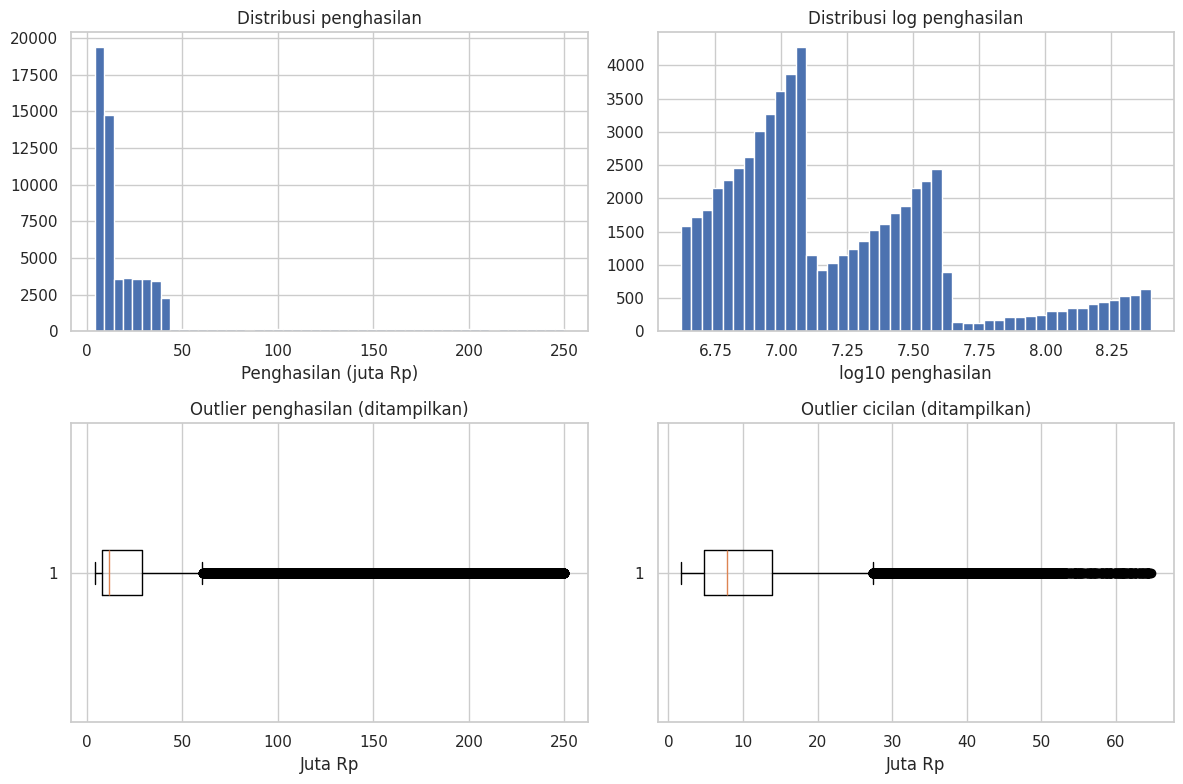

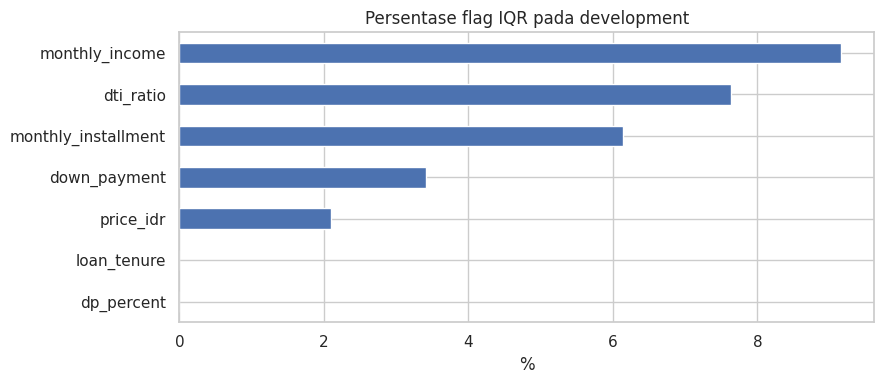

In [ ]:
cols = ['monthly_income','price_idr','down_payment','dp_percent','loan_tenure','monthly_installment','dti_ratio']
q1,q3 = dev[cols].quantile(.25),dev[cols].quantile(.75)
iqr = q3-q1
lower,upper = q1-1.5*iqr,q3+1.5*iqr
flags = dev[cols].lt(lower) | dev[cols].gt(upper)
outliers = pd.DataFrame({'q1':q1,'q3':q3,'lower':lower,'upper':upper,
                         'count':flags.sum(),'pct':flags.mean()*100})
display(dev[cols].describe().T)
display(outliers)
outliers.to_csv(OUT/'outlier_analysis.csv')
fig,ax=plt.subplots(2,2,figsize=(12,8))
ax[0,0].hist(dev.monthly_income/1e6, bins=50); ax[0,0].set(xlabel='Penghasilan (juta Rp)',title='Distribusi penghasilan')
ax[0,1].hist(np.log10(dev.monthly_income),bins=45); ax[0,1].set(xlabel='log10 penghasilan',title='Distribusi log penghasilan')
ax[1,0].boxplot(dev.monthly_income/1e6,vert=False,showfliers=True); ax[1,0].set(xlabel='Juta Rp',title='Outlier penghasilan (ditampilkan)')
ax[1,1].boxplot(dev.monthly_installment/1e6,vert=False,showfliers=True); ax[1,1].set(xlabel='Juta Rp',title='Outlier cicilan (ditampilkan)')
showfig('02_outliers')
outliers['pct'].sort_values().plot.barh(figsize=(9,4),title='Persentase flag IQR pada development')
plt.xlabel('%'); showfig('03_outlier_counts')

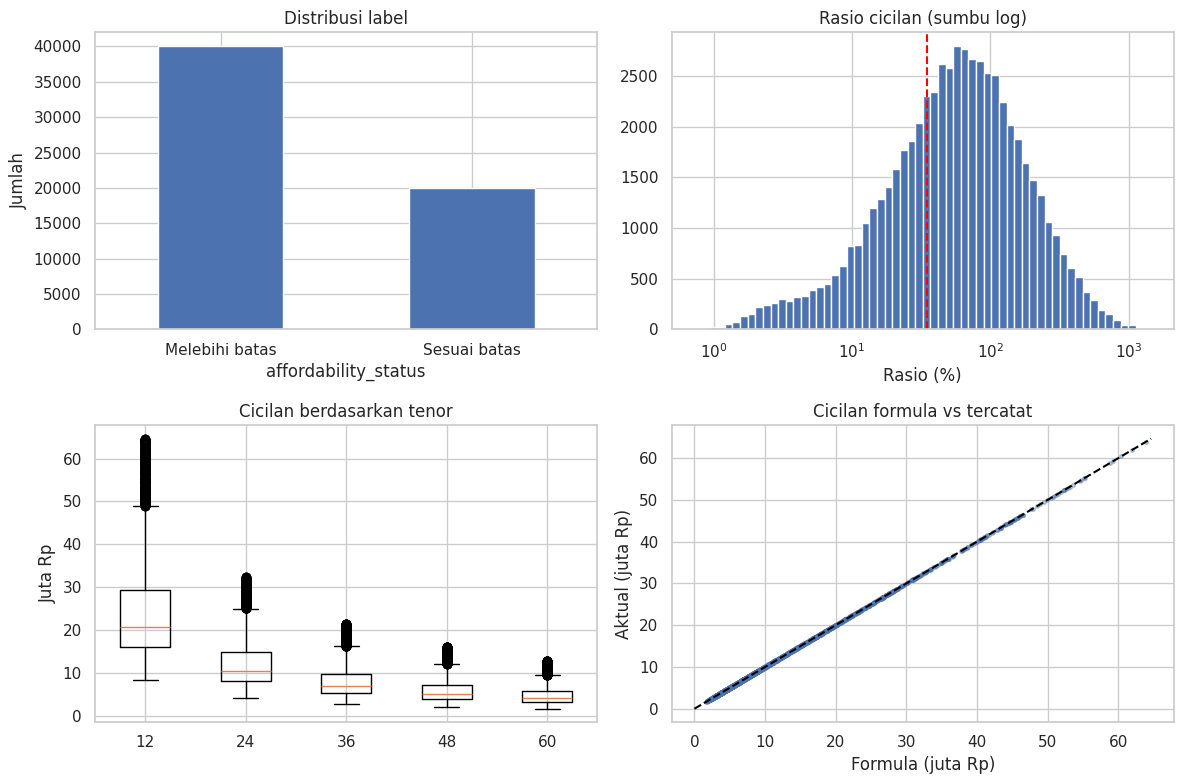

,transactions,median_price,median_installment,eligible_pct
company,,,,
BYD,7416,"450,000,000.0000","10,068,835.5000",23.9617
Daihatsu,7472,"250,000,000.0000","4,637,228.0000",49.0899
Honda,7583,"360,000,000.0000","9,659,385.0000",29.7508
Hyundai,7564,"550,000,000.0000","10,579,571.5000",25.0793
Mitsubishi,7710,"390,000,000.0000","8,889,767.5000",28.2101
Suzuki,7425,"280,000,000.0000","5,731,523.0000",41.8721
Toyota,7369,"320,000,000.0000","7,325,638.0000",34.5773
Wuling,7477,"320,000,000.0000","6,568,312.0000",34.6128


,transactions,median_price,median_installment,eligible_pct
body_style,,,,
Hatchback,15763,"290,000,000.0000","5,486,253.0000",42.9043
MPV,12075,"280,000,000.0000","6,032,589.0000",38.6915
Pickup,2284,"550,000,000.0000","10,674,945.0000",21.2785
SUV,26811,"430,000,000.0000","9,102,349.0000",28.4585
Sedan,3083,"700,000,000.0000","15,484,486.0000",15.1476


,transactions,median_price,median_installment,eligible_pct
loan_tenure,,,,
12,11973,"360,000,000.0000","20,668,036.0000",10.6740
24,11918,"360,000,000.0000","10,456,578.5000",23.1499
36,11992,"360,000,000.0000","6,903,340.0000",35.1985
48,12055,"350,000,000.0000","5,155,089.0000",44.1974
60,12078,"360,000,000.0000","4,148,856.0000",53.2538


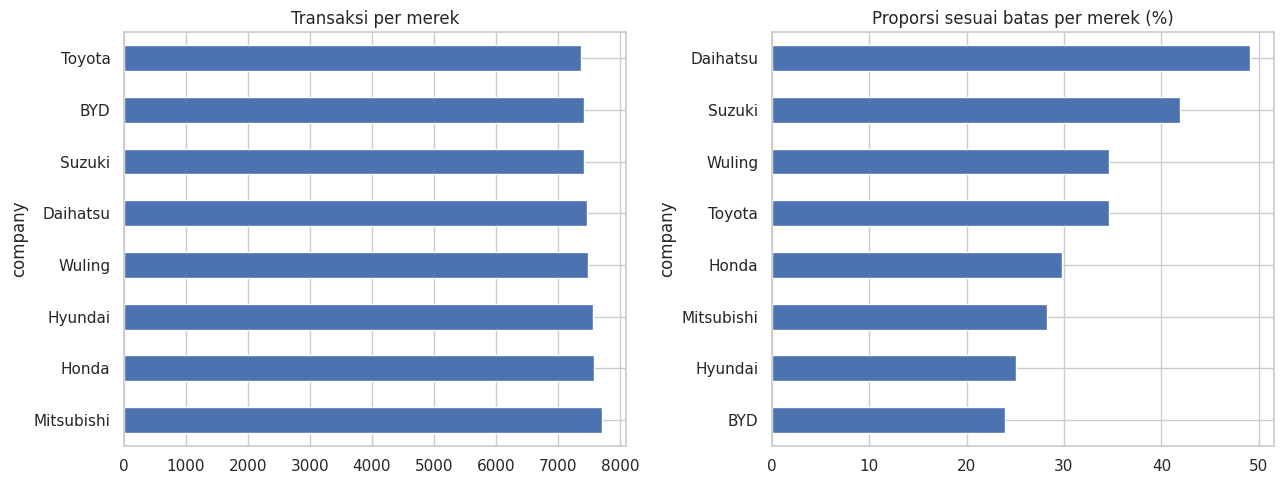

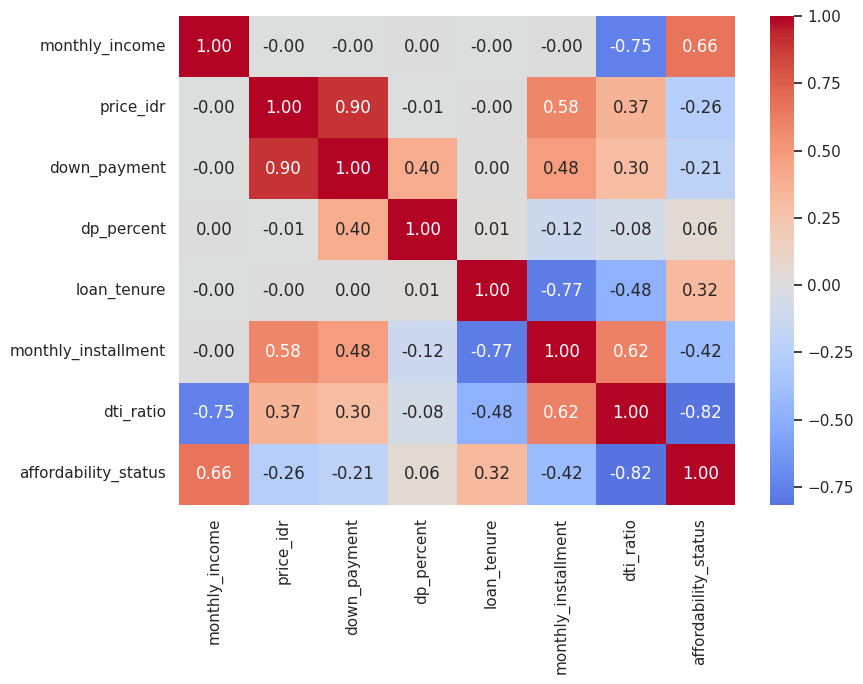

Harga per model berubah: 0
Engine & transmisi (audit kombinasi, bukan fitur):


transmission,Automatic,Manual
engine,,
1.0L NAT,634,682
1.0L Turbo,1191,1119
1.2L NAT,2534,2521
1.2L i-VTEC,654,641
1.5L Hybrid,618,576
1.5L MIVEC,2290,2343
1.5L MPI,1510,1517
1.5L NAT,5411,5521
1.5L Turbo,2649,2601


In [ ]:
fig,ax=plt.subplots(2,2,figsize=(12,8))
counts=dev.affordability_status.map({0:'Melebihi batas',1:'Sesuai batas'}).value_counts()
counts.plot.bar(ax=ax[0,0],rot=0); ax[0,0].set(title='Distribusi label',ylabel='Jumlah')
ax[0,1].hist(dev.dti_ratio,bins=np.geomspace(dev.dti_ratio.min(),dev.dti_ratio.max(),61)); ax[0,1].set_xscale("log"); ax[0,1].axvline(35,ls='--',color='red'); ax[0,1].set(title='Rasio cicilan (sumbu log)',xlabel='Rasio (%)')
ax[1,0].boxplot([g.monthly_installment/1e6 for _,g in dev.groupby("loan_tenure")]); ax[1,0].set_xticklabels(sorted(dev.loan_tenure.unique())); ax[1,0].set(title='Cicilan berdasarkan tenor',ylabel='Juta Rp')
plot_sample=dev.sample(min(3500,len(dev)),random_state=SEED)
ax[1,1].scatter(plot_sample.formula_installment/1e6,plot_sample.monthly_installment/1e6,s=7,alpha=.35)
mx=dev.monthly_installment.max()/1e6
ax[1,1].plot([0,mx],[0,mx],'--',color='black'); ax[1,1].set(title='Cicilan formula vs tercatat',xlabel='Formula (juta Rp)',ylabel='Aktual (juta Rp)')
showfig('04_financial_eda')
for c in ['company','body_style','loan_tenure']:
    display(dev.groupby(c).agg(transactions=('model','size'),median_price=('price_idr','median'),
                               median_installment=('monthly_installment','median'),
                               eligible_pct=('affordability_status',lambda x:100*x.mean())))
fig,ax=plt.subplots(1,2,figsize=(13,5))
dev.company.value_counts().plot.barh(ax=ax[0],title='Transaksi per merek')
dev.groupby('company').affordability_status.mean().mul(100).sort_values().plot.barh(ax=ax[1],title='Proporsi sesuai batas per merek (%)')
showfig('05_brand_eda')
plt.figure(figsize=(9,7)); sns.heatmap(dev[cols+['affordability_status']].corr(method='spearman'),annot=True,fmt='.2f',cmap='coolwarm',center=0); showfig('06_correlation')
print('Harga per model berubah:',(dev.groupby(['company','model']).price_idr.nunique()>1).sum())
print('Engine & transmisi (audit kombinasi, bukan fitur):'); display(pd.crosstab(dev.engine,dev.transmission))

### 6.1 Profil kategorikal dan distribusi frekuensi
EDA kategorikal memakai development set agar final test tetap terisolasi. Merek, model, tipe bodi, mesin, transmisi dan tenor dianalisis bersama kategori tambahan dari data mentah: provinsi, jenis pembelian, asuransi, warna dan trade-in. Kategori tambahan hanya digunakan untuk EDA; identitas dan kontak tidak digunakan. Frekuensi mencerminkan komposisi dataset, bukan permintaan pasar aktual. Missing ditampilkan sebagai Tidak tercatat.

,variable,categories,most_frequent,most_frequent_pct,unknown_count
0,company,8,Mitsubishi,12.8466,0
1,car_model,46,BYD | Dolphin,3.1275,0
2,body_style,5,SUV,44.6731,0
3,engine,15,Electric Motor,24.9300,0
4,transmission,2,Manual,50.0200,0
5,tenor_group,5,60,20.1246,0
6,province,14,Jawa Timur,12.4650,0
7,purchase_type,3,Business,33.4694,0
8,insurance_type,3,All Risk,55.2703,5936
9,color,6,White,16.8672,0


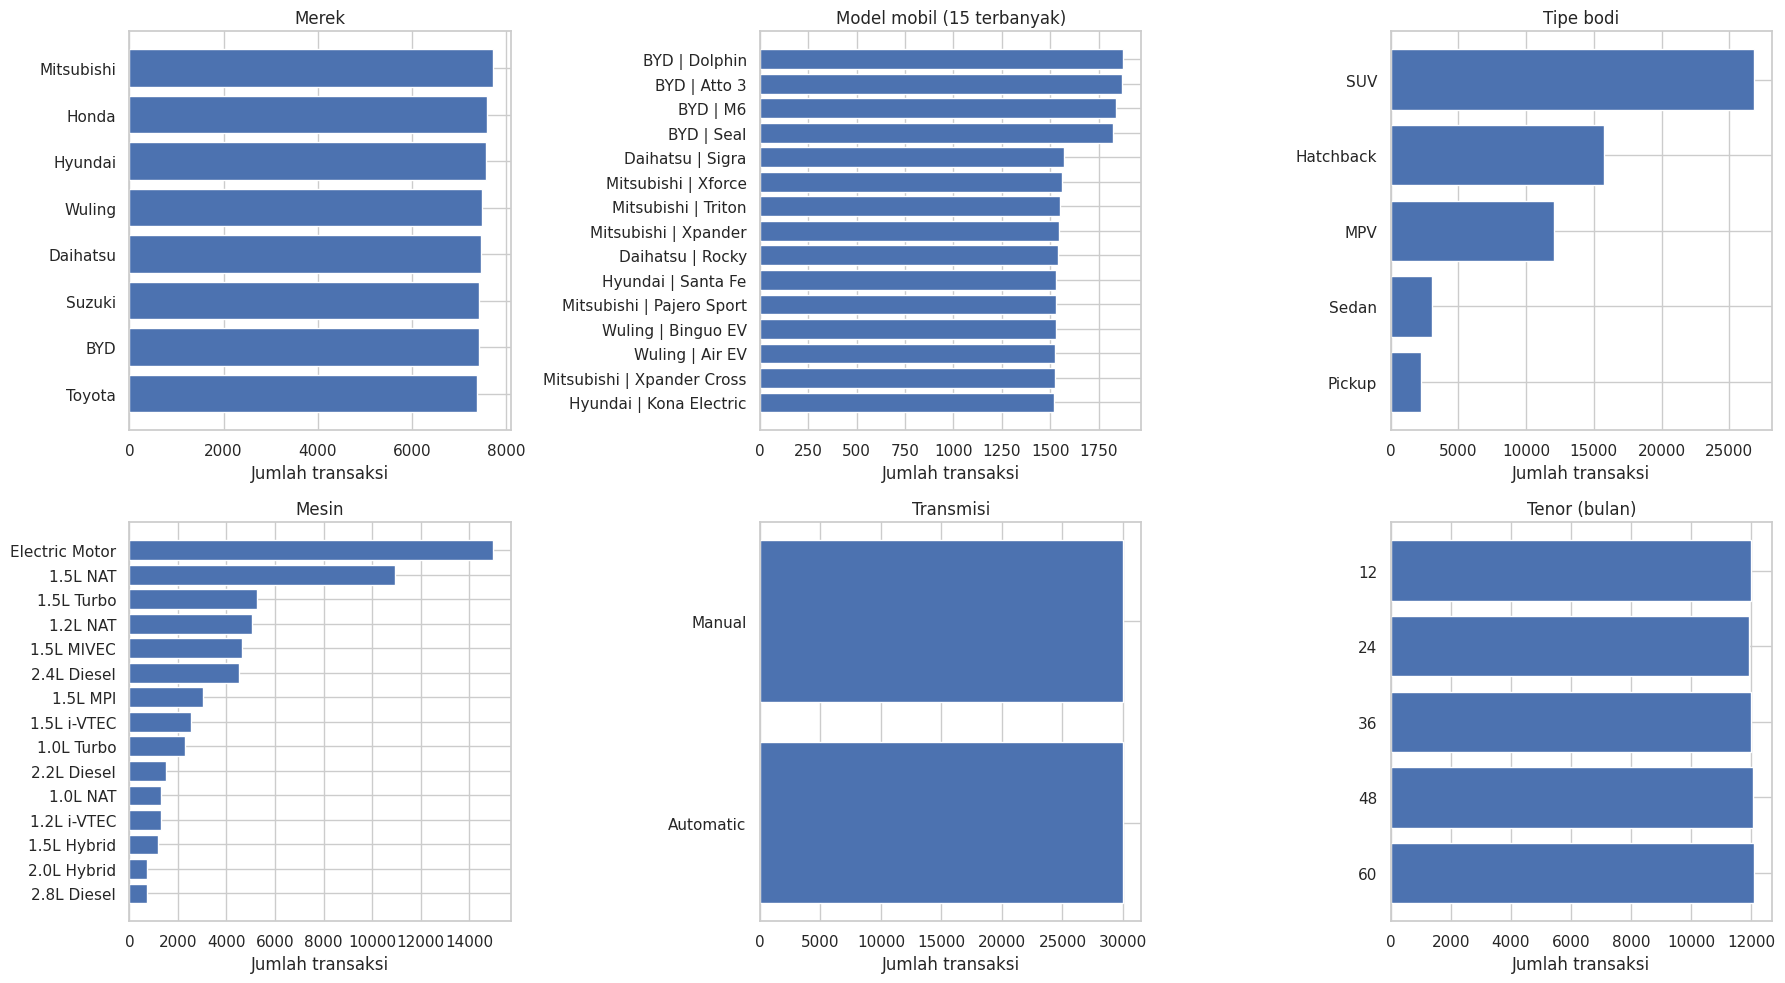

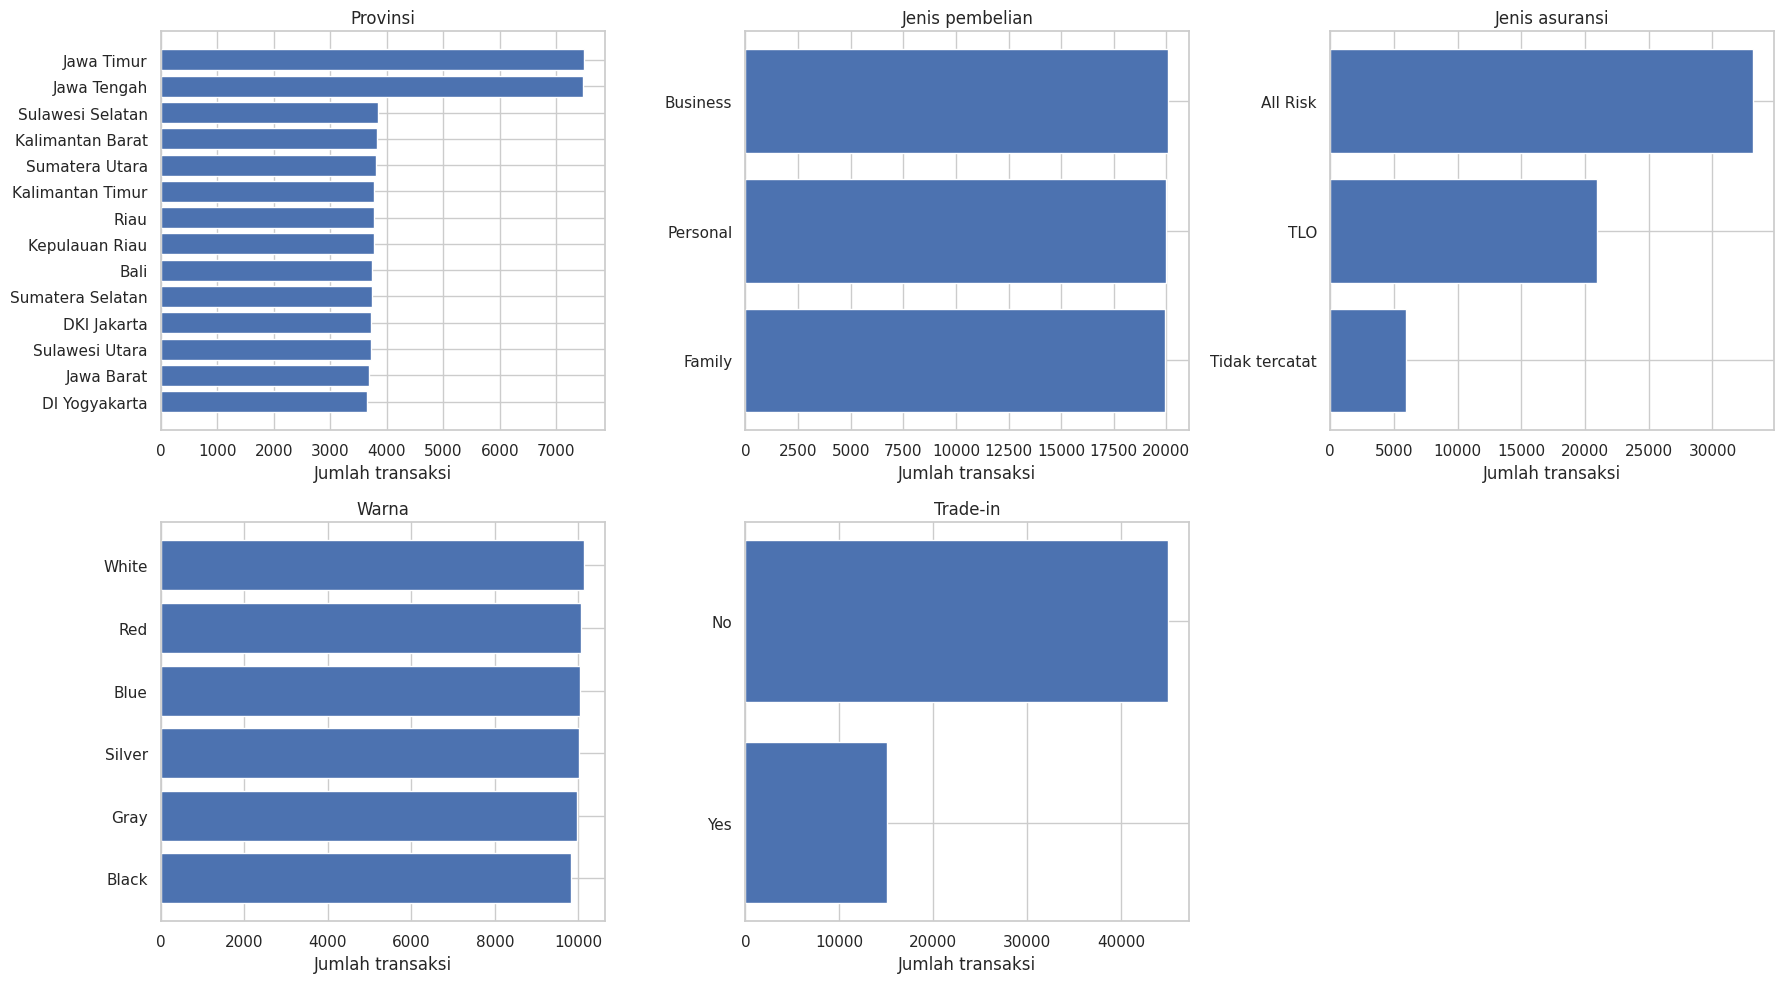

In [ ]:
cat_dev = dev.copy()
context_cols = {'Province':'province','Purchase_Type':'purchase_type','Insurance_Type':'insurance_type',
                'Color':'color','Trade_In':'trade_in'}
source_rows = credit.loc[valid.index[valid], ['Price (IDR)','Monthly_Installment',*context_cols]].reset_index(drop=True)
assert len(source_rows) == len(df)
np.testing.assert_array_equal(source_rows['Price (IDR)'],df.price_idr)
np.testing.assert_array_equal(source_rows['Monthly_Installment'],df.monthly_installment)
context = source_rows[list(context_cols)].rename(columns=context_cols).loc[cat_dev.index]
for field in context:
    cat_dev[field] = context[field].astype('string').str.strip().replace('',pd.NA).fillna('Tidak tercatat')
cat_dev['car_model'] = cat_dev.company.astype(str) + ' | ' + cat_dev.model.astype(str)
cat_dev['tenor_group'] = cat_dev.loan_tenure
cat_dev['status_label'] = cat_dev.affordability_status.map({0:'Melebihi batas',1:'Sesuai batas'})
cat_dev['installment_million'] = cat_dev.monthly_installment/1e6
cat_dev['price_million'] = cat_dev.price_idr/1e6
cat_fields = {'company':'Merek','car_model':'Model mobil','body_style':'Tipe bodi','engine':'Mesin',
              'transmission':'Transmisi','tenor_group':'Tenor (bulan)','province':'Provinsi',
              'purchase_type':'Jenis pembelian','insurance_type':'Jenis asuransi','color':'Warna','trade_in':'Trade-in'}
cat_profile, cat_frequency = [], []
for field,label in cat_fields.items():
    freq = cat_dev[field].value_counts(dropna=False)
    cat_profile.append({'variable':field,'categories':len(freq),'most_frequent':str(freq.index[0]),
                        'most_frequent_pct':100*freq.iloc[0]/len(cat_dev),
                        'unknown_count':int(cat_dev[field].isin(['Unknown','Tidak tercatat']).sum())})
    cat_frequency.extend({'variable':field,'category':str(k),'transactions':int(v),'share_pct':100*v/len(cat_dev)} for k,v in freq.items())
cat_profile = pd.DataFrame(cat_profile)
cat_frequency = pd.DataFrame(cat_frequency)
display(cat_profile)
cat_profile.to_csv(OUT/'categorical_profile.csv',index=False)
cat_frequency.to_csv(OUT/'categorical_frequency.csv',index=False)
for part,fields in [('utama',list(cat_fields)[:6]),('tambahan',list(cat_fields)[6:])]:
    fig,axes = plt.subplots(2,3,figsize=(18,10))
    for ax,field in zip(axes.flat,fields):
        counts_cat = cat_dev[field].value_counts()
        counts_cat = counts_cat.sort_index(ascending=False) if field=='tenor_group' else counts_cat.head(15).sort_values()
        ax.barh(counts_cat.index.astype(str),counts_cat.values)
        ax.set(title=cat_fields[field]+(' (15 terbanyak)' if field=='car_model' else ''),xlabel='Jumlah transaksi')
    for ax in list(axes.flat)[len(fields):]: ax.axis('off')
    showfig('07a_categorical_distribution_'+part)

### 6.2 Analisis finansial per kategori
Bandingkan jumlah transaksi, harga, penghasilan, rata-rata dan median cicilan, kuartil cicilan, median rasio cicilan dan persentase sesuai batas 35%. Semua kategori diekspor; model mobil ditampilkan 15 dengan transaksi terbanyak agar grafik terbaca. Persentase dihitung terhadap jumlah transaksi masing-masing kategori.

Merek


,transactions,median_price_million,median_income_million,mean_installment_million,median_installment_million,q1_installment_million,q3_installment_million,median_dti_pct,eligible_count,transaction_share_pct,eligible_pct,not_eligible_count,not_eligible_pct
company,,,,,,,,,,,,,
Mitsubishi,7710,390.0000,11.7971,12.1450,8.8898,5.7115,16.1412,67.6245,2175,12.8466,28.2101,5535,71.7899
Honda,7583,360.0000,11.6736,13.4656,9.6594,5.2626,16.7428,66.1632,2256,12.6350,29.7508,5327,70.2492
Hyundai,7564,550.0000,11.6898,14.5480,10.5796,6.9813,18.0896,79.5893,1897,12.6033,25.0793,5667,74.9207
Wuling,7477,320.0000,11.7441,9.0890,6.5683,4.5968,11.6502,53.5142,2588,12.4583,34.6128,4889,65.3872
Daihatsu,7472,250.0000,11.8186,6.2930,4.6372,3.2099,8.1141,35.7848,3668,12.4500,49.0899,3804,50.9101
Suzuki,7425,280.0000,11.7605,7.8889,5.7315,3.7562,9.8073,43.7532,3109,12.3717,41.8721,4316,58.1279
BYD,7416,450.0000,11.7693,13.9248,10.0688,6.9570,17.5474,81.4667,1777,12.3567,23.9617,5639,76.0383
Toyota,7369,320.0000,11.7604,9.9837,7.3256,4.6997,12.6908,54.4021,2548,12.2784,34.5773,4821,65.4227


Model mobil


,transactions,median_price_million,median_income_million,mean_installment_million,median_installment_million,q1_installment_million,q3_installment_million,median_dti_pct,eligible_count,transaction_share_pct,eligible_pct,not_eligible_count,not_eligible_pct
car_model,,,,,,,,,,,,,
BYD | Dolphin,1877,420.0000,11.7557,11.2253,8.1536,5.7348,13.2843,67.3994,534,3.1275,28.4497,1343,71.5503
BYD | Atto 3,1872,520.0000,11.6576,13.7444,10.0542,6.9473,16.1844,84.3242,443,3.1192,23.6645,1429,76.3355
BYD | M6,1841,450.0000,11.7690,11.8532,8.5860,6.1283,13.9481,71.1657,490,3.0675,26.6160,1351,73.3840
BYD | Seal,1826,700.0000,11.9338,18.9731,13.8656,9.4757,22.1996,111.8568,310,3.0425,16.9770,1516,83.0230
Daihatsu | Sigra,1571,190.0000,11.3241,4.9959,3.6151,2.5937,5.8948,30.9849,871,2.6176,55.4424,700,44.5576
Mitsubishi | Xforce,1562,390.0000,11.8485,10.1427,7.2363,5.1613,11.9493,61.6675,479,2.6026,30.6658,1083,69.3342
Mitsubishi | Triton,1548,550.0000,11.6648,14.4450,10.6566,7.5509,16.8717,87.9259,330,2.5793,21.3178,1218,78.6822
Mitsubishi | Xpander,1545,300.0000,11.9271,7.9298,5.6009,4.0074,9.3496,47.0746,610,2.5743,39.4822,935,60.5178
Daihatsu | Rocky,1542,260.0000,12.0792,7.0069,5.1293,3.5080,8.1668,39.2274,697,2.5693,45.2010,845,54.7990


Tipe bodi


,transactions,median_price_million,median_income_million,mean_installment_million,median_installment_million,q1_installment_million,q3_installment_million,median_dti_pct,eligible_count,transaction_share_pct,eligible_pct,not_eligible_count,not_eligible_pct
body_style,,,,,,,,,,,,,
SUV,26811,430.0000,11.7321,12.4941,9.1023,5.7035,16.1341,68.6555,7630,44.6731,28.4585,19181,71.5415
Hatchback,15763,290.0000,11.7548,7.6035,5.4863,3.6837,9.7278,42.4206,6763,26.2647,42.9043,9000,57.0957
MPV,12075,280.0000,11.7702,8.3521,6.0326,4.0370,10.4078,47.5355,4672,20.1196,38.6915,7403,61.3085
Sedan,3083,700.0000,11.8770,21.8703,15.4845,11.2260,28.1110,128.3207,467,5.1370,15.1476,2616,84.8524
Pickup,2284,550.0000,11.6498,14.4781,10.6749,7.5358,16.9196,88.1336,486,3.8057,21.2785,1798,78.7215


... (12 outputs left out)

Warna


,transactions,median_price_million,median_income_million,mean_installment_million,median_installment_million,q1_installment_million,q3_installment_million,median_dti_pct,eligible_count,transaction_share_pct,eligible_pct,not_eligible_count,not_eligible_pct
color,,,,,,,,,,,,,
White,10123,360.0000,11.8213,10.8795,7.8816,4.8352,13.7402,56.2612,3463,16.8672,34.2092,6660,65.7908
Red,10054,350.0000,11.7809,10.9155,7.8612,4.8470,13.8620,58.0901,3332,16.7522,33.1410,6722,66.8590
Blue,10030,360.0000,11.7164,10.8155,7.8346,4.7859,13.6974,57.8838,3328,16.7122,33.1805,6702,66.8195
Silver,10022,360.0000,11.7537,10.9785,7.8965,4.8312,13.9803,58.1268,3239,16.6989,32.3189,6783,67.6811
Gray,9955,360.0000,11.7894,10.9744,7.8622,4.8049,13.8631,55.8712,3401,16.5872,34.1637,6554,65.8363
Black,9832,360.0000,11.6259,11.0400,7.8900,4.8306,13.9763,59.2767,3255,16.3823,33.1062,6577,66.8938


Trade-in


,transactions,median_price_million,median_income_million,mean_installment_million,median_installment_million,q1_installment_million,q3_installment_million,median_dti_pct,eligible_count,transaction_share_pct,eligible_pct,not_eligible_count,not_eligible_pct
trade_in,,,,,,,,,,,,,
No,44981,360.0000,11.7726,10.9016,7.8641,4.8326,13.8116,57.4320,14994,74.9483,33.3341,29987,66.6659
Yes,15035,360.0000,11.6752,11.0286,7.8812,4.7860,13.9934,57.8971,5024,25.0517,33.4154,10011,66.5846


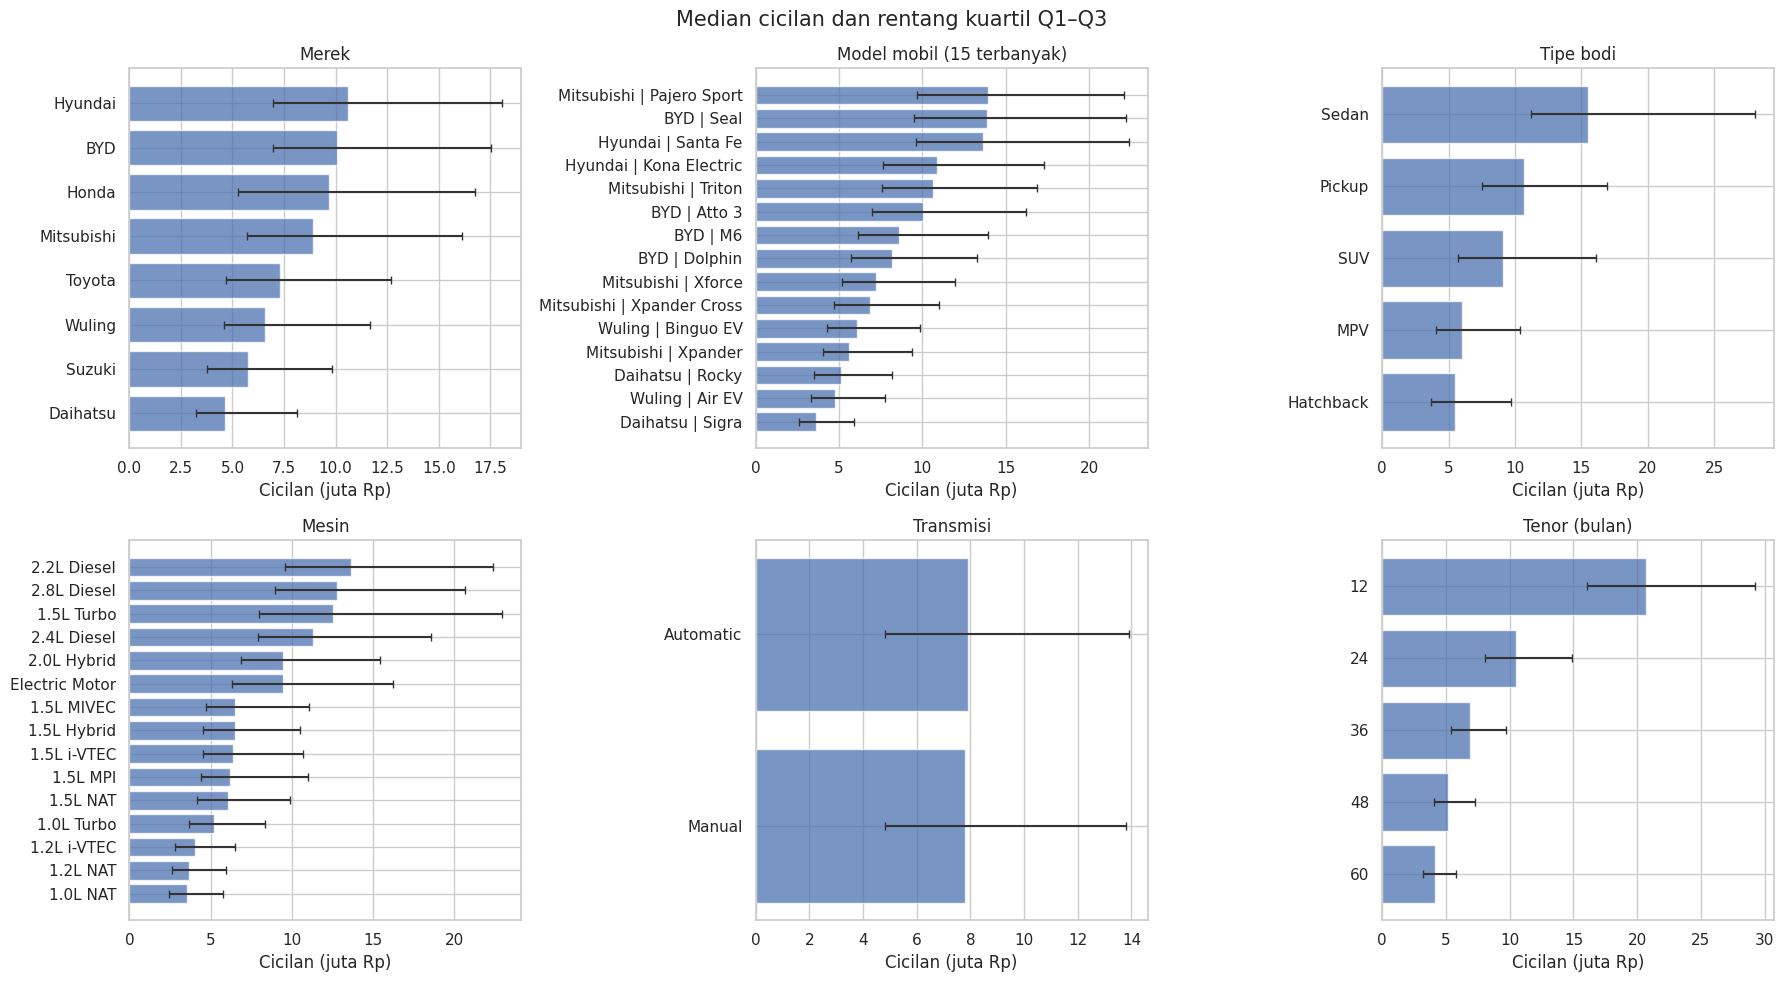

In [ ]:
cat_summaries = {}
for field,label in cat_fields.items():
    summary = cat_dev.groupby(field,observed=True,dropna=False).agg(
        transactions=('affordability_status','size'),median_price_million=('price_million','median'),
        median_income_million=('monthly_income',lambda x:x.median()/1e6),
        mean_installment_million=('installment_million','mean'),median_installment_million=('installment_million','median'),
        q1_installment_million=('installment_million',lambda x:x.quantile(.25)),
        q3_installment_million=('installment_million',lambda x:x.quantile(.75)),
        median_dti_pct=('dti_ratio','median'),eligible_count=('affordability_status','sum'))
    summary['transaction_share_pct'] = 100*summary.transactions/len(cat_dev)
    summary['eligible_pct'] = 100*summary.eligible_count/summary.transactions
    summary['not_eligible_count'] = summary.transactions-summary.eligible_count
    summary['not_eligible_pct'] = 100-summary.eligible_pct
    summary = summary.sort_index() if field=='tenor_group' else summary.sort_values('transactions',ascending=False)
    assert summary.transactions.sum()==len(cat_dev)
    cat_summaries[field] = summary
    print(label)
    display(summary.head(15) if field=='car_model' else summary)
cat_summary_all = pd.concat([s.rename_axis('category').reset_index().assign(variable=k) for k,s in cat_summaries.items()],ignore_index=True)
cat_summary_all.to_csv(OUT/'categorical_financial_summary.csv',index=False)
fig,axes = plt.subplots(2,3,figsize=(18,10))
for ax,field in zip(axes.flat,list(cat_fields)[:6]):
    plot = cat_summaries[field].head(15) if field=='car_model' else cat_summaries[field]
    plot = plot.iloc[::-1] if field=='tenor_group' else plot.sort_values('median_installment_million')
    pos = np.arange(len(plot))
    ax.barh(pos,plot.median_installment_million,alpha=.75)
    ax.errorbar(plot.median_installment_million,pos,xerr=np.vstack([plot.median_installment_million-plot.q1_installment_million,
        plot.q3_installment_million-plot.median_installment_million]),fmt='none',ecolor='#333333',capsize=3)
    ax.set(yticks=pos,yticklabels=plot.index.astype(str),xlabel='Cicilan (juta Rp)',title=cat_fields[field]+(' (15 terbanyak)' if field=='car_model' else ''))
fig.suptitle('Median cicilan dan rentang kuartil Q1–Q3',fontsize=15)
showfig('07b_categorical_installment_summary')

### 6.3 Analisis bivariat kategori, cicilan dan kemampuan bayar
Boxplot menampilkan outlier dan menggunakan skala log untuk keterbacaan. Stacked bar membandingkan proporsi label di dalam masing-masing kategori. Garis putus-putus menunjukkan proporsi sesuai batas seluruh development set. Label ini tidak menunjukkan keputusan persetujuan kredit aktual.

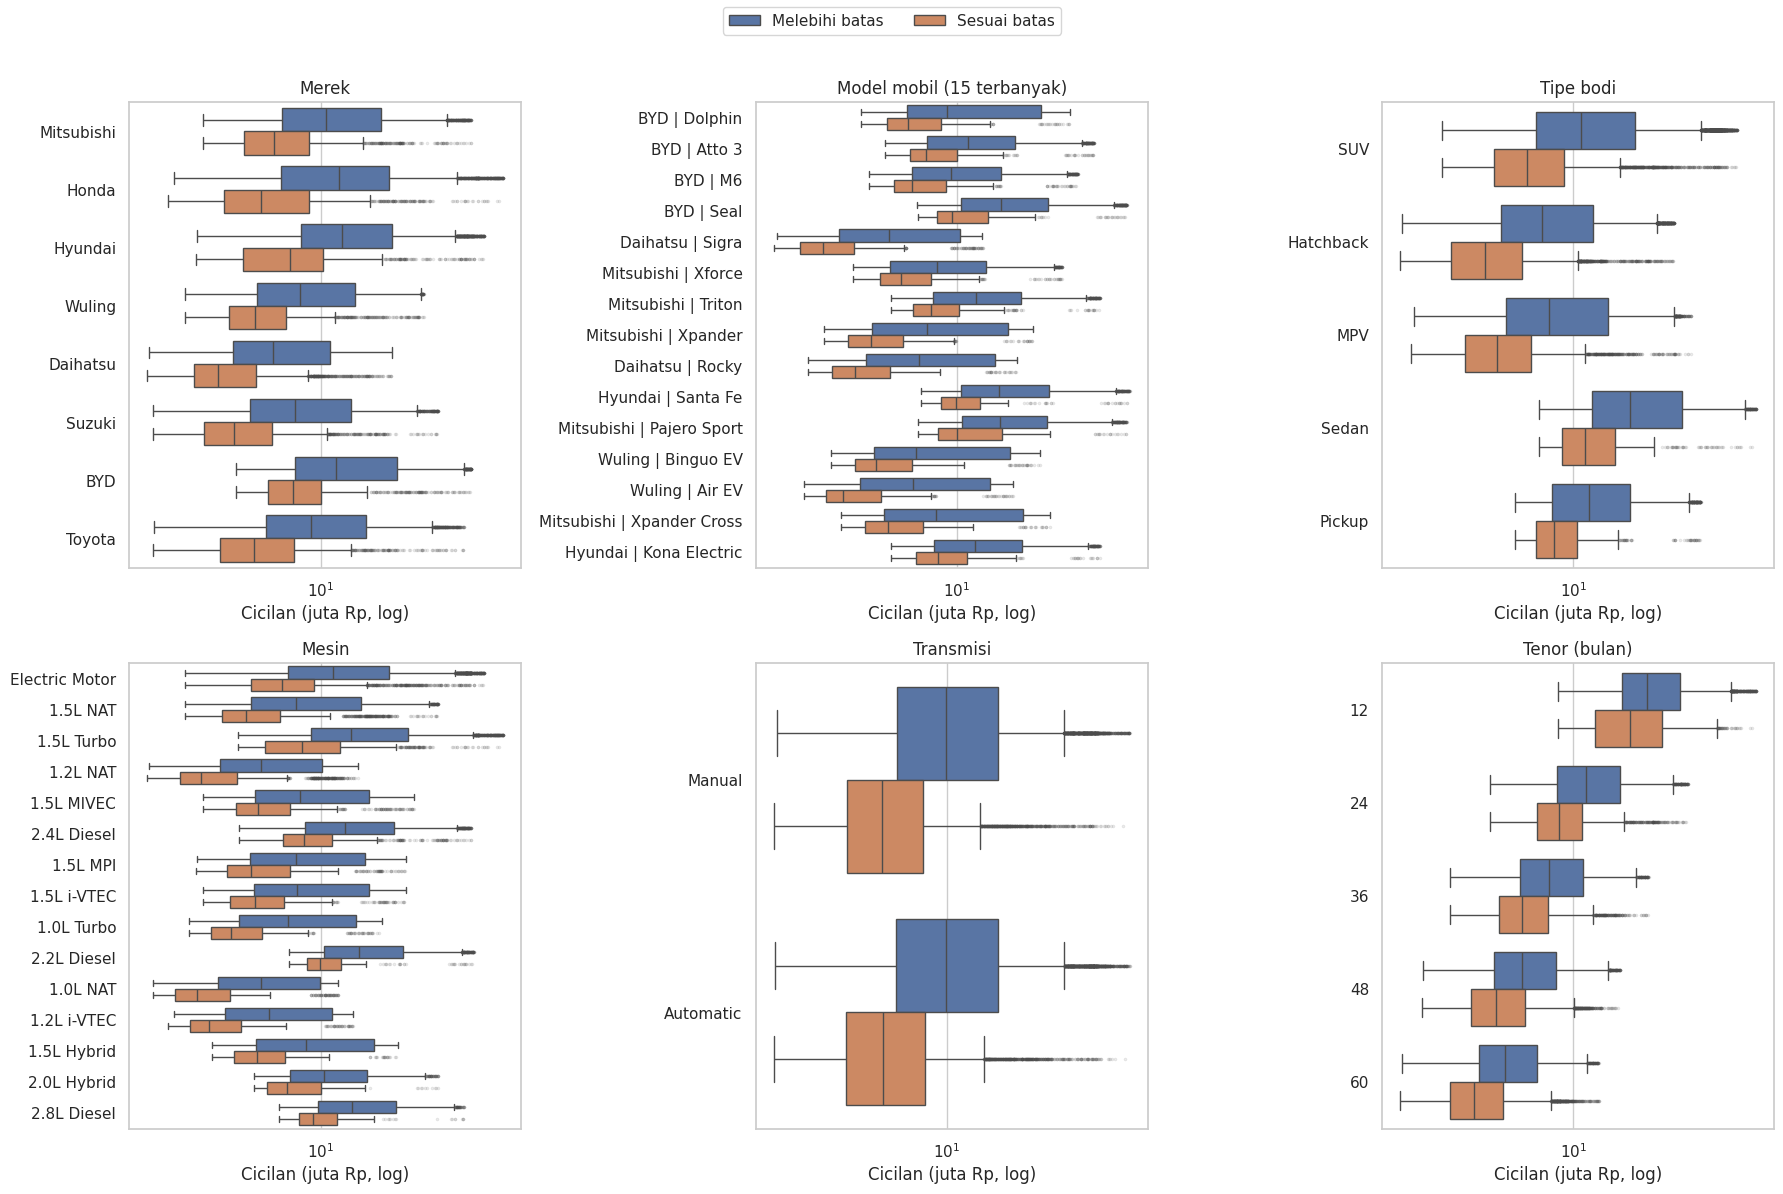

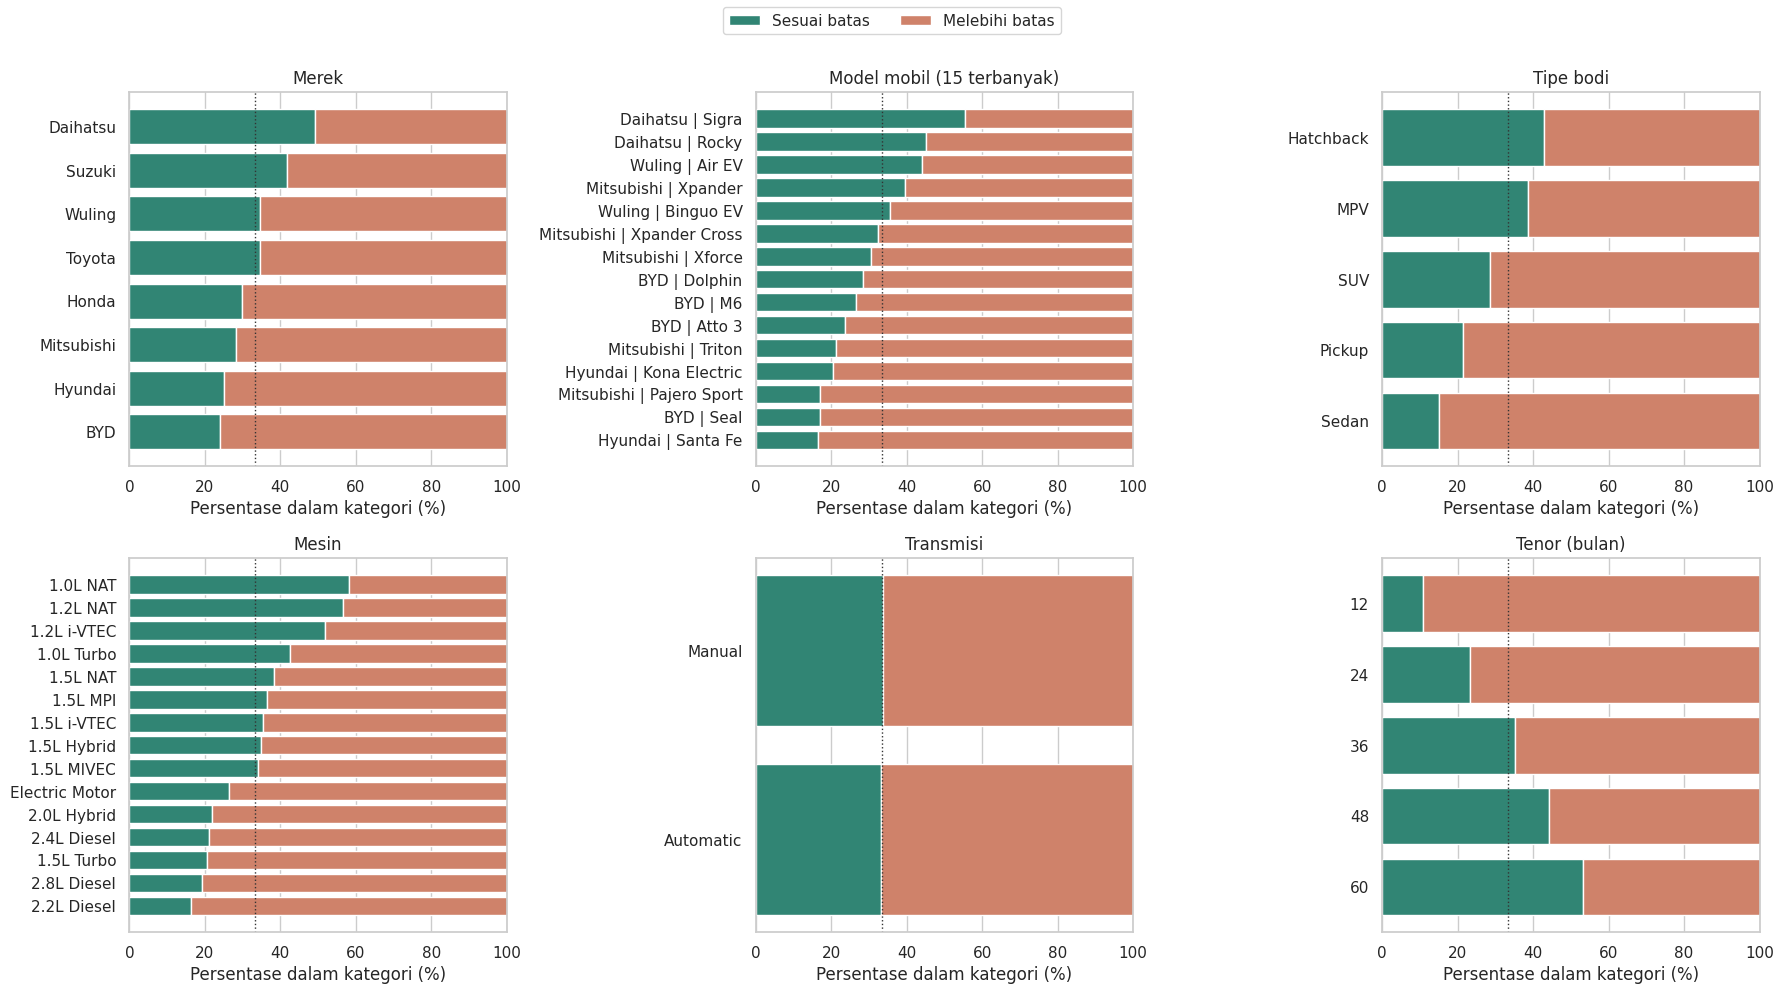

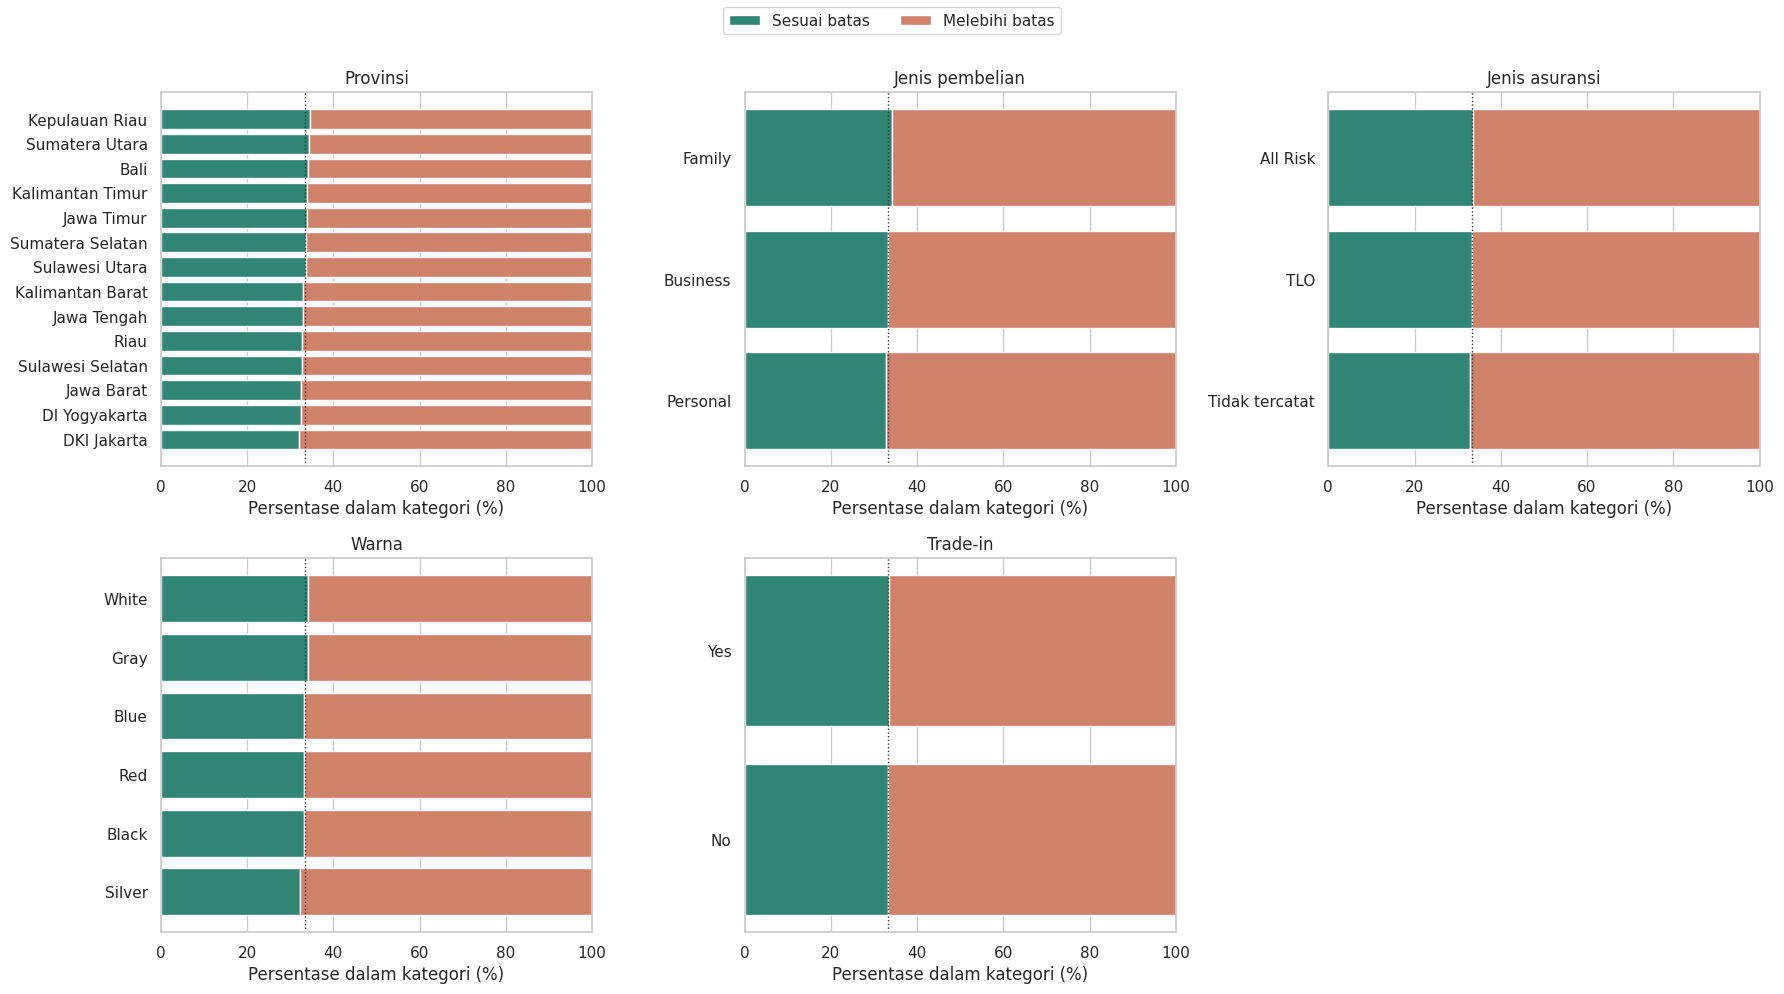

In [ ]:
fig,axes = plt.subplots(2,3,figsize=(18,12))
for ax,field in zip(axes.flat,list(cat_fields)[:6]):
    order = sorted(cat_dev[field].unique()) if field=='tenor_group' else cat_dev[field].value_counts().head(15).index.tolist()
    view = cat_dev[cat_dev[field].isin(order)].copy()
    view[field] = view[field].astype(str)
    sns.boxplot(data=view,x='installment_million',y=field,order=[str(x) for x in order],hue='status_label',
        hue_order=['Melebihi batas','Sesuai batas'],showfliers=True,flierprops={'markersize':1.5,'alpha':.15},ax=ax)
    ax.set_xscale('log')
    ax.set(title=cat_fields[field]+(' (15 terbanyak)' if field=='car_model' else ''),xlabel='Cicilan (juta Rp, log)',ylabel='')
    if ax.get_legend() is not None: ax.get_legend().remove()
handles,labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles,labels,loc='upper center',ncol=2)
fig.tight_layout(rect=[0,0,1,.95]); plt.savefig(FIG/'07c_categorical_boxplots.png',dpi=140,bbox_inches='tight'); plt.show(); plt.close()
for part,fields in [('utama',list(cat_fields)[:6]),('tambahan',list(cat_fields)[6:])]:
    fig,axes = plt.subplots(2,3,figsize=(18,10))
    for ax,field in zip(axes.flat,fields):
        plot = cat_summaries[field].head(15) if field=='car_model' else cat_summaries[field]
        plot = plot.iloc[::-1] if field=='tenor_group' else plot.sort_values('eligible_pct')
        ax.barh(plot.index.astype(str),plot.eligible_pct,label='Sesuai batas',color='#318574')
        ax.barh(plot.index.astype(str),plot.not_eligible_pct,left=plot.eligible_pct,label='Melebihi batas',color='#cf826a')
        ax.axvline(cat_dev.affordability_status.mean()*100,color='#333333',linestyle=':',linewidth=1)
        ax.set(xlim=(0,100),xlabel='Persentase dalam kategori (%)',title=cat_fields[field]+(' (15 terbanyak)' if field=='car_model' else ''))
    for ax in list(axes.flat)[len(fields):]: ax.axis('off')
    handles,labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles,labels,loc='upper center',ncol=2)
    fig.tight_layout(rect=[0,0,1,.95]); plt.savefig(FIG/f'07d_status_{part}.png',dpi=140,bbox_inches='tight'); plt.show(); plt.close()

### 6.4 Crosstab dan heatmap antar kategori
Merek × tipe bodi dan mesin × transmisi membantu memahami struktur katalog serta menemukan kombinasi yang perlu diverifikasi. Heatmap merek × tenor menunjukkan persentase sesuai batas pada tenor yang sama, beserta jumlah transaksi. Perbandingan tetap deskriptif karena harga dan penghasilan dapat berbeda.

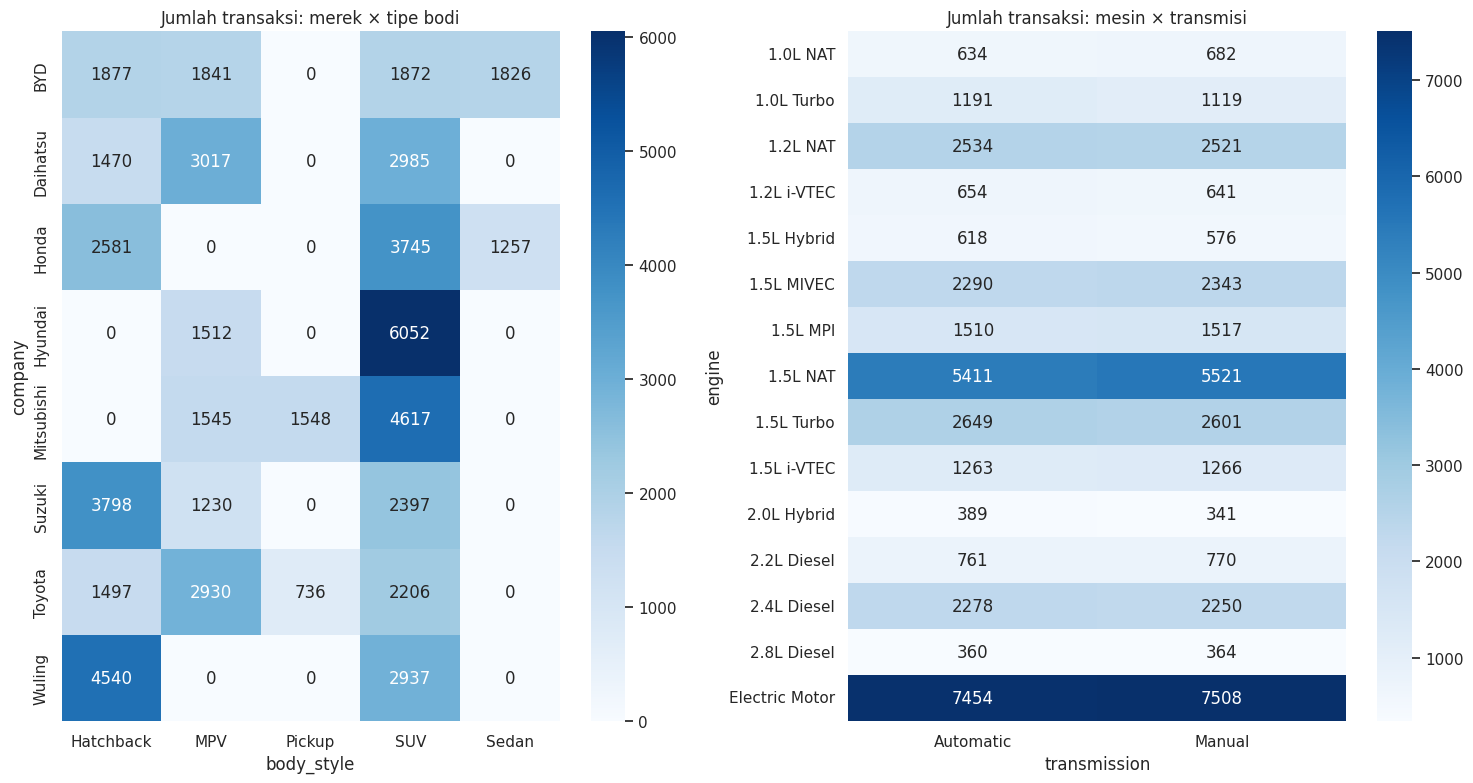

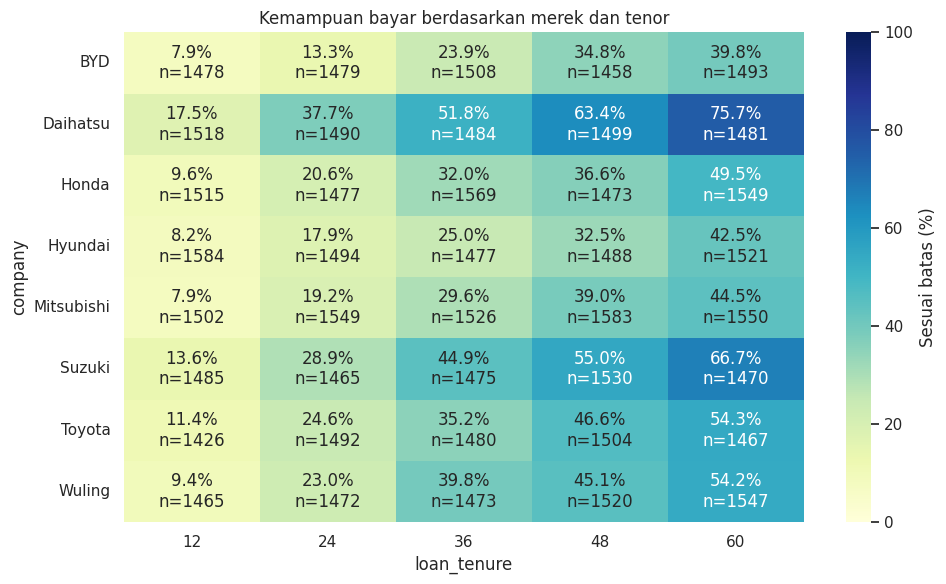

Kombinasi mesin dan transmisi perlu diverifikasi terhadap katalog asli, bukan otomatis dihapus.


In [ ]:
brand_body = pd.crosstab(cat_dev.company,cat_dev.body_style)
engine_trans = pd.crosstab(cat_dev.engine,cat_dev.transmission)
brand_tenor_count = pd.crosstab(cat_dev.company,cat_dev.loan_tenure)
brand_tenor_rate = cat_dev.pivot_table(index='company',columns='loan_tenure',values='affordability_status',aggfunc='mean')*100
for name,table in [('brand_body',brand_body),('engine_transmission',engine_trans),('brand_tenor_count',brand_tenor_count),('brand_tenor_eligible_pct',brand_tenor_rate)]:
    table.to_csv(OUT/f'categorical_{name}.csv')
fig,axes = plt.subplots(1,2,figsize=(15,8))
sns.heatmap(brand_body,annot=True,fmt='d',cmap='Blues',ax=axes[0]); axes[0].set_title('Jumlah transaksi: merek × tipe bodi')
sns.heatmap(engine_trans,annot=True,fmt='d',cmap='Blues',ax=axes[1]); axes[1].set_title('Jumlah transaksi: mesin × transmisi')
showfig('07e_categorical_crosstab')
annotations = pd.DataFrame('',index=brand_tenor_rate.index,columns=brand_tenor_rate.columns)
for brand in annotations.index:
    for tenor in annotations.columns:
        rate = brand_tenor_rate.loc[brand,tenor]
        if pd.notna(rate): annotations.loc[brand,tenor] = f'{rate:.1f}%\nn={brand_tenor_count.loc[brand,tenor]}'
plt.figure(figsize=(10,6))
sns.heatmap(brand_tenor_rate,annot=annotations,fmt='',cmap='YlGnBu',vmin=0,vmax=100,cbar_kws={'label':'Sesuai batas (%)'})
plt.title('Kemampuan bayar berdasarkan merek dan tenor'); showfig('07f_brand_tenor_eligibility')
status_crosstab = pd.concat([pd.crosstab(cat_dev[field],cat_dev.status_label).rename_axis('category').reset_index().assign(variable=field) for field in cat_fields],ignore_index=True)
status_crosstab.to_csv(OUT/'categorical_status_crosstab.csv',index=False)
print('Kombinasi mesin dan transmisi perlu diverifikasi terhadap katalog asli, bukan otomatis dihapus.')

### 6.5 Ukuran asosiasi dan interpretasi
Cramér’s V terkoreksi bias mengukur asosiasi kategori dengan label kemampuan bayar. Eta squared (η²) mengukur proporsi variasi nominal cicilan yang berkaitan dengan perbedaan rata-rata antar kategori. Keduanya berada pada rentang 0–1. Asosiasi tidak membuktikan kausalitas atau manfaat prediktif tambahan. Harga, DP, tenor dan penghasilan sudah menentukan target pada dataset ini; kategori bisa menjadi proksi harga. Analisis tidak mengubah fitur model, model terpilih, atau kompatibilitas deployment.

,variable,label,cramers_v_status,eta_squared_installment
5,tenor_group,Tenor (bulan),0.3197,0.5746
1,car_model,Model mobil,0.2630,0.2934
3,engine,Mesin,0.2355,0.1796
0,company,Merek,0.1703,0.0962
2,body_style,Tipe bodi,0.1681,0.1419
9,color,Warna,0.0106,0.0001
7,purchase_type,Jenis pembelian,0.0105,0.0000
4,transmission,Transmisi,0.0049,0.0000
6,province,Provinsi,0.0000,0.0003
8,insurance_type,Jenis asuransi,0.0000,0.0000


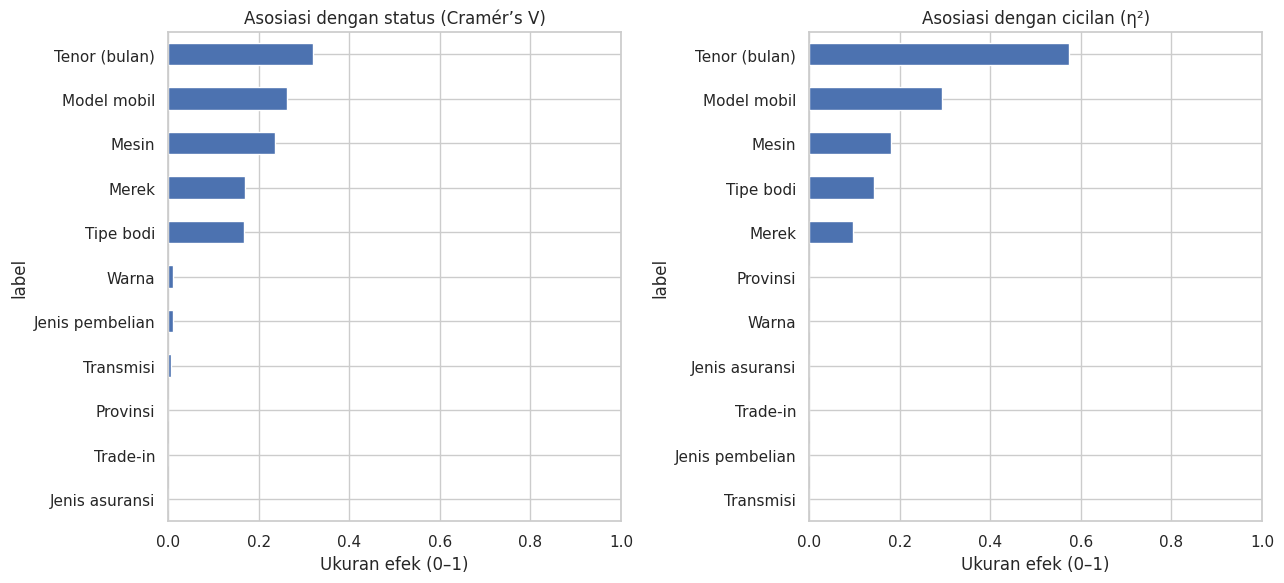

Proporsi sesuai batas keseluruhan development: 33.35%
Merek: tertinggi Daihatsu (49.09%), terendah BYD (23.96%).
Tipe bodi: tertinggi Hatchback (42.90%), terendah Sedan (15.15%).
Transmisi: tertinggi Manual (33.65%), terendah Automatic (33.05%).
Tenor (bulan): tertinggi 60 (53.25%), terendah 12 (10.67%).
Asosiasi terbesar cramers_v_status: Tenor (bulan) (0.3197)
Asosiasi terbesar eta_squared_installment: Tenor (bulan) (0.5746)
Interpretasi: deskriptif; fitur model tetap finansial.


In [ ]:
from scipy.stats import chi2_contingency

def corrected_cramers_v(table):
    observed = table.to_numpy()
    n = observed.sum()
    r,k = observed.shape
    if n<=1 or min(r,k)<2: return np.nan
    chi2 = chi2_contingency(observed,correction=False)[0]
    phi2 = max(0,chi2/n-(k-1)*(r-1)/(n-1))
    denom = min(r-(r-1)**2/(n-1)-1,k-(k-1)**2/(n-1)-1)
    return np.sqrt(phi2/denom) if denom>0 else np.nan

def installment_eta_squared(field):
    groups = cat_dev.groupby(field,observed=True).installment_million.agg(['size','mean'])
    grand_mean = cat_dev.installment_million.mean()
    ss_between = (groups['size']*(groups['mean']-grand_mean)**2).sum()
    ss_total = ((cat_dev.installment_million-grand_mean)**2).sum()
    return ss_between/ss_total if ss_total>0 else np.nan

cat_assoc = pd.DataFrame([{'variable':field,'label':label,
    'cramers_v_status':corrected_cramers_v(pd.crosstab(cat_dev[field],cat_dev.affordability_status)),
    'eta_squared_installment':installment_eta_squared(field)} for field,label in cat_fields.items()]).sort_values('cramers_v_status',ascending=False)
display(cat_assoc)
cat_assoc.to_csv(OUT/'categorical_association.csv',index=False)
fig,axes = plt.subplots(1,2,figsize=(13,6))
for ax,metric,title in zip(axes,['cramers_v_status','eta_squared_installment'],['Asosiasi dengan status (Cramér’s V)','Asosiasi dengan cicilan (η²)']):
    cat_assoc.set_index('label')[metric].sort_values().plot.barh(ax=ax,title=title,xlim=(0,1))
    ax.set_xlabel('Ukuran efek (0–1)')
showfig('07g_categorical_association')
print(f'Proporsi sesuai batas keseluruhan development: {100*cat_dev.affordability_status.mean():.2f}%')
for field in ['company','body_style','transmission','tenor_group']:
    ranked = cat_summaries[field].sort_values('eligible_pct',ascending=False)
    print(f'{cat_fields[field]}: tertinggi {ranked.index[0]} ({ranked.eligible_pct.iloc[0]:.2f}%), terendah {ranked.index[-1]} ({ranked.eligible_pct.iloc[-1]:.2f}%).')
for metric in ['cramers_v_status','eta_squared_installment']:
    strongest = cat_assoc.loc[cat_assoc[metric].idxmax()]
    print(f"Asosiasi terbesar {metric}: {strongest['label']} ({strongest[metric]:.4f})")
print('Interpretasi: deskriptif; fitur model tetap finansial.')

## 7. Model kandidat dan ruang hyperparameter
Regresi: Linear, Polynomial (Ridge dengan ekspansi polynomial), Decision Tree, Random Forest, KNN, Gradient Boosting, XGBoost. Klasifikasi: Logistic, Decision Tree, Random Forest, KNN, Gradient Boosting, XGBoost. Dummy dan formula menjadi baseline. Model tree tidak memerlukan scaling. Target nominal tetap dalam rupiah (XGBoost memakai histogram). Class imbalance moderat: macro-F1 sebagai metrik utama dan class weight diuji untuk model yang mendukung; SMOTE tidak otomatis digunakan karena dapat menciptakan skema tenor/harga yang tidak valid.

In [ ]:
def pipe(model, scale=False):
    return Pipeline([('scale',StandardScaler() if scale else 'passthrough'),('model',model)])

def specs(task):
    reg = task=='reg'
    DT = DecisionTreeRegressor if reg else DecisionTreeClassifier
    RF = RandomForestRegressor if reg else RandomForestClassifier
    GB = GradientBoostingRegressor if reg else GradientBoostingClassifier
    KNN = KNeighborsRegressor if reg else KNeighborsClassifier
    XGB = XGBRegressor if reg else XGBClassifier
    linear = pipe(LinearRegression(),True) if reg else pipe(LogisticRegression(max_iter=1500,random_state=SEED),True)
    tree_grid = {'model__max_depth':[6,12,20,None], 'model__min_samples_leaf':[1,3,8,15], 'model__min_samples_split':[2,10,20]}
    rf_grid = {'model__n_estimators':[60,100,150], 'model__max_depth':[10,18,None],
               'model__min_samples_leaf':[1,3,8], 'model__max_features':[.7,1.0,'sqrt'], 'model__min_samples_split':[2,8]}
    if not reg:
        tree_grid['model__class_weight']=[None,'balanced']
        rf_grid['model__class_weight']=[None,'balanced']
    result = {
        'Linear Regression' if reg else 'Logistic Regression': (linear,
            {'scale':[StandardScaler(),RobustScaler()],'model__fit_intercept':[True,False]} if reg else
            {'scale':[StandardScaler(),RobustScaler()],'model__C':[.1,1,10,100], 'model__class_weight':[None,'balanced']}),
        'Decision Tree':(pipe(DT(random_state=SEED)),tree_grid),
        'Random Forest':(pipe(RF(n_estimators=80,random_state=SEED,n_jobs=1)),rf_grid),
        'KNN':(pipe(KNN(n_neighbors=5,weights='distance',n_jobs=1),True),
               {'scale':[StandardScaler(),RobustScaler()],'model__n_neighbors':[3,5,9,15,25],'model__weights':['uniform','distance'],'model__p':[1,2]}),
        'Gradient Boosting':(pipe(GB(n_estimators=80,random_state=SEED)),
            {'model__n_estimators':[60,100,150],'model__learning_rate':[.05,.1,.15],'model__max_depth':[2,3,5],'model__min_samples_leaf':[2,8,15],'model__subsample':[.8,1.0]}),
        'XGBoost':(pipe(XGB(n_estimators=100,max_depth=5,tree_method='hist',n_jobs=1,random_state=SEED,verbosity=0)),
            {'model__n_estimators':[80,150,250],'model__max_depth':[3,5,7],'model__learning_rate':[.04,.1,.2],'model__min_child_weight':[1,5,10],'model__subsample':[.8,1.0],'model__reg_lambda':[1,5,10]})}
    if reg:
        result['Polynomial Regression']=(Pipeline([('poly',PolynomialFeatures(2,include_bias=False)),('scale',StandardScaler()),('model',Ridge(alpha=1))]),
                                         {'poly__degree':[2,3],'model__alpha':[.01,.1,1,10]})
    return result

print('Regresi:',list(specs('reg')))
print('Klasifikasi:',list(specs('clf')))

Regresi: ['Linear Regression', 'Decision Tree', 'Random Forest', 'KNN', 'Gradient Boosting', 'XGBoost', 'Polynomial Regression']
Klasifikasi: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'KNN', 'Gradient Boosting', 'XGBoost']


## 8. Cross-validation dan hyperparameter tuning
Tiga skenario menggunakan baris dan fold identik untuk perbandingan adil. `RandomizedSearchCV` memakai empat kombinasi per kandidat (anggaran eksplorasi terbatas, bukan jaminan optimum global). Hasil baseline memakai konfigurasi awal yang eksplisit. Pemilihan model hanya dari mean CV MAE (regresi, lebih kecil lebih baik) dan macro-F1 (klasifikasi, lebih besar lebih baik); simpangan baku dan gap train–validation dilaporkan. Jika performa sama, kandidat lebih sederhana diprioritaskan. Final test tidak digunakan di tahap ini.

In [ ]:
records, fitted, search_details = [], {}, []

def summarize(task,name,scenario,feature_set,result,index=None,params=None):
    get = lambda field: float(result[field][index]) if index is not None else float(np.mean(result[field]))
    std = float(result['std_test_main'][index]) if index is not None else float(np.std(result['test_main']))
    prefix = 'mean_' if index is not None else ''
    train_score = get(prefix+'train_main')
    val_score = get(prefix+'test_main')
    sign = -1 if task=='reg' else 1
    rec = dict(task=task,model=name,scenario=scenario,feature_set=feature_set,
               train_primary=sign*train_score,cv_primary=sign*val_score,cv_std=std,
               generalization_gap=(train_score-val_score),params=str(params or {}))
    for metric in scoring[task]:
        if metric != 'main':
            rec['cv_'+metric] = get(prefix+'test_'+metric)*(-1 if metric=='rmse' else 1)
    records.append(rec)

for task in ('reg','clf'):
    y=search[target[task]]
    X=make_features(search,task,'raw')
    for name,(model,grid) in specs(task).items():
        result=cross_validate(model,X,y,cv=cv[task],scoring=scoring[task],return_train_score=True,n_jobs=N_JOBS,error_score='raise')
        summarize(task,name,'1_raw_baseline','raw',result)
        fitted[(task,name,'1_raw_baseline')]=clone(model)
    for scenario,feature_set in [('2_raw_tuned','raw'),('3_financial_tuned','financial')]:
        X=make_features(search,task,feature_set)
        for name,(model,grid) in specs(task).items():
            tuner=RandomizedSearchCV(model,grid,n_iter=N_ITER,cv=cv[task],scoring=scoring[task],
                refit='main',return_train_score=True,n_jobs=N_JOBS,random_state=SEED,error_score='raise')
            tuner.fit(X,y)
            summarize(task,name,scenario,feature_set,tuner.cv_results_,tuner.best_index_,tuner.best_params_)
            fitted[(task,name,scenario)]=clone(tuner.best_estimator_)
            details=pd.DataFrame(tuner.cv_results_)[['params','mean_test_main','std_test_main','mean_train_main','rank_test_main']].copy()
            details.insert(0,'task',task); details.insert(1,'model',name); details.insert(2,'scenario',scenario)
            search_details.append(details)
            print(task,scenario,name,':',round(records[-1]['cv_primary'],5),flush=True)
cv_results=pd.DataFrame(records)
cv_results.to_csv(OUT/'cv_model_comparison.csv',index=False)
pd.concat(search_details,ignore_index=True).to_csv(OUT/'hyperparameter_search.csv',index=False)
for task in ('reg','clf'):
    display(cv_results.query('task == @task').sort_values('cv_primary',ascending=task=='reg').drop(columns=['params','task']))

reg 2_raw_tuned Linear Regression : 3305354.94524
reg 2_raw_tuned Decision Tree : 95683.10941
reg 2_raw_tuned Random Forest : 35917.88845
reg 2_raw_tuned KNN : 46615.0162
reg 2_raw_tuned Gradient Boosting : 143662.67817
reg 2_raw_tuned XGBoost : 47392.94297
reg 2_raw_tuned Polynomial Regression : 416308.60994
reg 3_financial_tuned Linear Regression : 0.25327
reg 3_financial_tuned Decision Tree : 12059.23423
reg 3_financial_tuned Random Forest : 5954.56493
reg 3_financial_tuned KNN : 48342.75785
reg 3_financial_tuned Gradient Boosting : 79757.16307
reg 3_financial_tuned XGBoost : 28079.50195
reg 3_financial_tuned Polynomial Regression : 3806.96775
clf 2_raw_tuned Logistic Regression : 0.93739
clf 2_raw_tuned Decision Tree : 0.96583
clf 2_raw_tuned Random Forest : 0.9779
clf 2_raw_tuned KNN : 0.97842
clf 2_raw_tuned Gradient Boosting : 0.98256
clf 2_raw_tuned XGBoost : 0.98688
clf 3_financial_tuned Logistic Regression : 0.99916
clf 3_financial_tuned Decision Tree : 1.0
clf 3_financial_tu

,model,scenario,feature_set,train_primary,cv_primary,cv_std,generalization_gap,cv_r2,cv_rmse,cv_accuracy,cv_balanced_accuracy,cv_precision,cv_recall
14,Linear Regression,3_financial_tuned,financial,0.2531,0.2533,0.0032,0.0002,1.0000,0.2917,NaN,NaN,NaN,NaN
20,Polynomial Regression,3_financial_tuned,financial,"3,778.0954","3,806.9677",34.2248,28.8724,1.0000,"6,006.8677",NaN,NaN,NaN,NaN
16,Random Forest,3_financial_tuned,financial,"3,975.7341","5,954.5649",593.1485,"1,978.8308",1.0000,"34,716.6880",NaN,NaN,NaN,NaN
15,Decision Tree,3_financial_tuned,financial,"7,993.9570","12,059.2342",882.8762,"4,065.2772",1.0000,"55,588.5487",NaN,NaN,NaN,NaN
2,Random Forest,1_raw_baseline,raw,"10,339.2806","25,975.2573","1,331.7423","15,635.9767",1.0000,"61,303.9518",NaN,NaN,NaN,NaN
3,KNN,1_raw_baseline,raw,-0.0000,"26,854.5690","1,347.0749","26,854.5690",0.9999,"78,099.5155",NaN,NaN,NaN,NaN
1,Decision Tree,1_raw_baseline,raw,-0.0000,"27,937.6815","1,725.8163","27,937.6815",0.9999,"65,815.8131",NaN,NaN,NaN,NaN
19,XGBoost,3_financial_tuned,financial,"17,156.2008","28,079.5020",728.5216,"10,923.3012",1.0000,"62,691.4352",NaN,NaN,NaN,NaN
9,Random Forest,2_raw_tuned,raw,"14,795.6552","35,917.8885","1,853.9475","21,122.2332",0.9999,"95,604.1067",NaN,NaN,NaN,NaN
10,KNN,2_raw_tuned,raw,"31,193.1494","46,615.0162","2,030.5138","15,421.8668",0.9998,"117,944.7022",NaN,NaN,NaN,NaN


,model,scenario,feature_set,train_primary,cv_primary,cv_std,generalization_gap,cv_r2,cv_rmse,cv_accuracy,cv_balanced_accuracy,cv_precision,cv_recall
37,Gradient Boosting,3_financial_tuned,financial,1.0000,1.0000,0.0000,0.0000,NaN,NaN,1.0000,1.0000,1.0000,1.0000
35,Random Forest,3_financial_tuned,financial,1.0000,1.0000,0.0000,0.0000,NaN,NaN,1.0000,1.0000,1.0000,1.0000
34,Decision Tree,3_financial_tuned,financial,1.0000,1.0000,0.0000,0.0000,NaN,NaN,1.0000,1.0000,1.0000,1.0000
33,Logistic Regression,3_financial_tuned,financial,0.9993,0.9992,0.0005,0.0002,NaN,NaN,0.9992,0.9991,0.9993,0.9985
38,XGBoost,3_financial_tuned,financial,0.9983,0.9979,0.0009,0.0003,NaN,NaN,0.9982,0.9975,0.9990,0.9955
32,XGBoost,2_raw_tuned,raw,0.9999,0.9869,0.0017,0.0130,NaN,NaN,0.9883,0.9869,0.9823,0.9828
26,XGBoost,1_raw_baseline,raw,1.0000,0.9851,0.0031,0.0149,NaN,NaN,0.9868,0.9851,0.9803,0.9800
31,Gradient Boosting,2_raw_tuned,raw,0.9940,0.9826,0.0025,0.0115,NaN,NaN,0.9845,0.9822,0.9782,0.9753
36,KNN,3_financial_tuned,financial,0.9876,0.9806,0.0015,0.0070,NaN,NaN,0.9828,0.9804,0.9748,0.9735
23,Random Forest,1_raw_baseline,raw,1.0000,0.9786,0.0037,0.0214,NaN,NaN,0.9809,0.9788,0.9706,0.9723


## 9. Baseline non-ML dan pemilihan model
Baseline dummy menunjukkan performa minimum. Rumus cicilan dan aturan 35% dievaluasi pada validation fold yang sama. Formula tidak membutuhkan fitting. Pemilihan model ML tetap dilakukan terpisah dari baseline non-ML agar kontribusi penelitian terlihat.

,task,method,cv_primary,cv_std
0,reg,Dummy,"6,018,267.5452","128,289.4863"
1,reg,Formula / rule,0.0000,0.0000
2,clf,Dummy,0.3999,0.0001
3,clf,Formula / rule,1.0000,0.0000


reg ML terbaik: Linear Regression 3_financial_tuned 0.2532725385167869


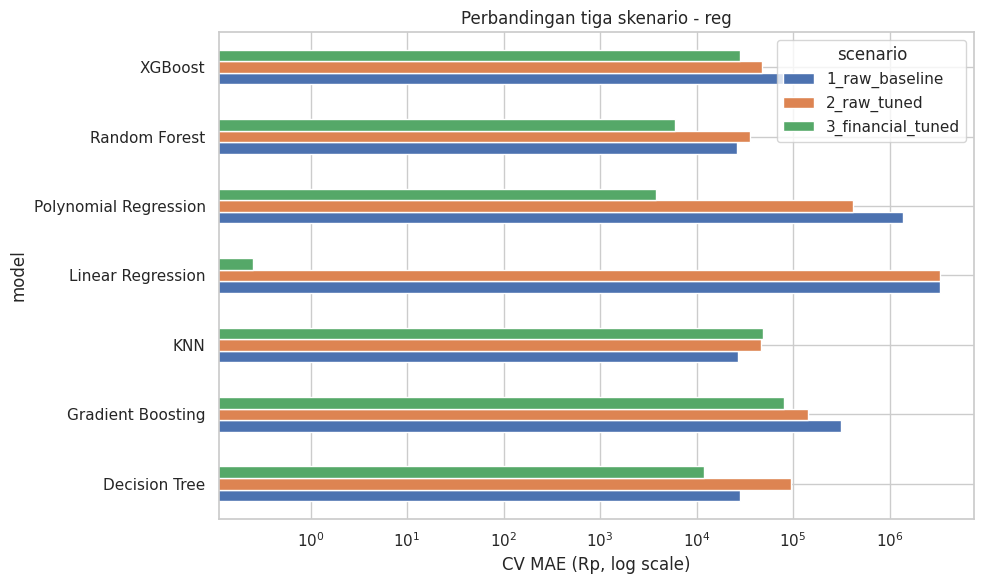

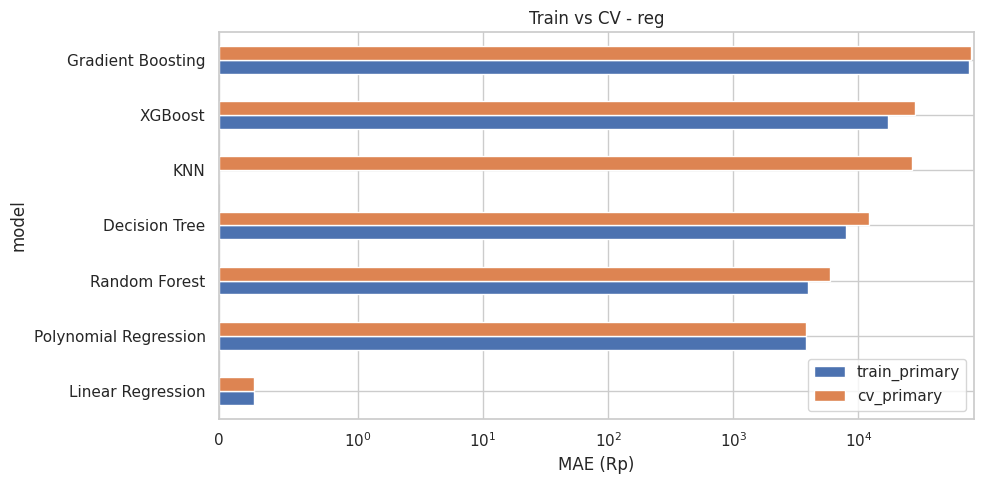

clf ML terbaik: Decision Tree 3_financial_tuned 1.0


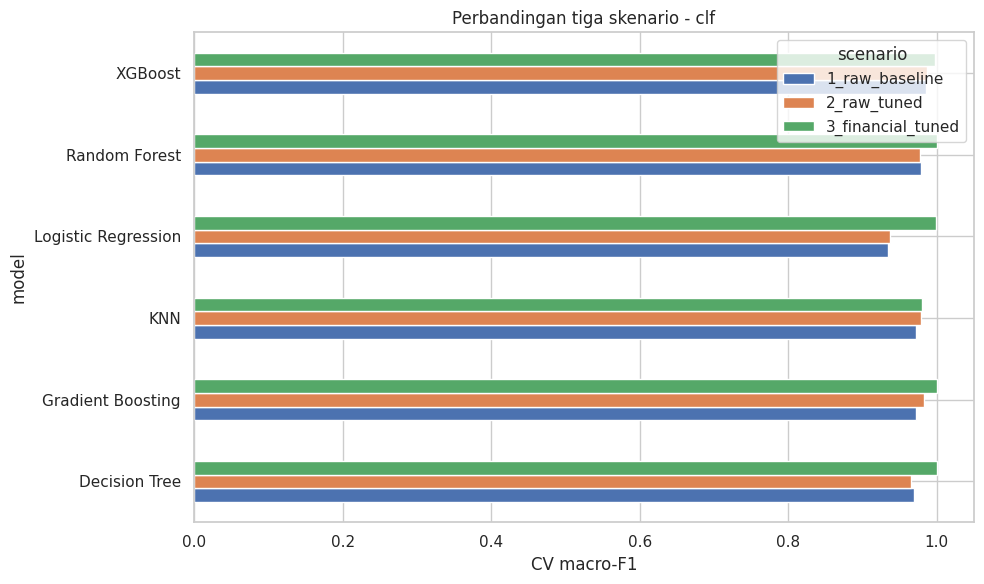

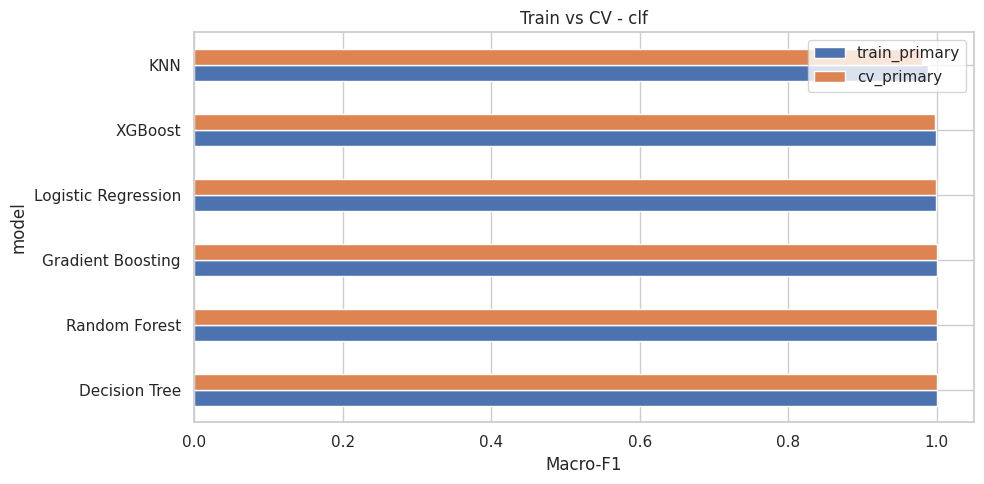

In [ ]:
baseline_records=[]
for task in ('reg','clf'):
    X=make_features(search,task,'raw'); y=search[target[task]]
    dummy=DummyRegressor(strategy='median') if task=='reg' else DummyClassifier(strategy='most_frequent')
    res=cross_validate(dummy,X,y,cv=cv[task],scoring=scoring[task],n_jobs=N_JOBS)
    baseline_records.append({'task':task,'method':'Dummy','cv_primary':float(np.mean(res['test_main']))*(-1 if task=='reg' else 1),'cv_std':float(np.std(res['test_main']))})
    values=[]
    for _,va in cv[task].split(X,y):
        fold=search.iloc[va]
        pred=formula_installment(fold) if task=='reg' else formula_status(fold)
        values.append(mean_absolute_error(fold[target[task]],pred) if task=='reg' else f1_score(fold[target[task]],pred,average='macro'))
    baseline_records.append({'task':task,'method':'Formula / rule','cv_primary':np.mean(values),'cv_std':np.std(values)})
baselines=pd.DataFrame(baseline_records); display(baselines); baselines.to_csv(OUT/'baseline_cv.csv',index=False)
complexity={'Linear Regression':0,'Logistic Regression':0,'Polynomial Regression':1,'Decision Tree':2,'KNN':3,'Random Forest':4,'Gradient Boosting':5,'XGBoost':6}
selected={}; raw_selected={}
for task in ('reg','clf'):
    table=cv_results.query('task == @task').copy()
    table['complexity']=table.model.map(complexity)
    table=table.sort_values(['cv_primary','complexity','cv_std'],ascending=[task=='reg',True,True])
    selected[task]=table.iloc[0].to_dict()
    raw_selected[task]=table.query('feature_set == "raw"').iloc[0].to_dict()
    print(task, 'ML terbaik:',selected[task]['model'], selected[task]['scenario'],selected[task]['cv_primary'])
    pivot=table.pivot(index='model',columns='scenario',values='cv_primary')
    if task=='reg':
        pivot.plot.barh(figsize=(10,6),logx=True); plt.xlabel('CV MAE (Rp, log scale)')
    else:
        pivot.plot.barh(figsize=(10,6)); plt.xlabel('CV macro-F1')
    plt.title('Perbandingan tiga skenario - '+task); showfig('07_cv_'+task)
    best_per_model=table.sort_values('cv_primary',ascending=task=='reg').drop_duplicates('model')
    best_per_model.set_index('model')[['train_primary','cv_primary']].plot.barh(figsize=(10,5))
    if task=='reg': plt.xscale('symlog',linthresh=1)
    plt.xlabel('MAE (Rp)' if task=='reg' else 'Macro-F1'); plt.title('Train vs CV - '+task); showfig('08_train_cv_'+task)

## 10. Learning curve dan diagnosis fitting
Learning curve memakai kandidat ML terpilih dan kandidat fitur asli terbaik (jika berbeda), pada development sample. Gap besar dapat menunjukkan overfitting; train dan validation sama-sama buruk dapat menunjukkan underfitting. Gap kecil saja tidak menjamin generalisasi distribusi baru.

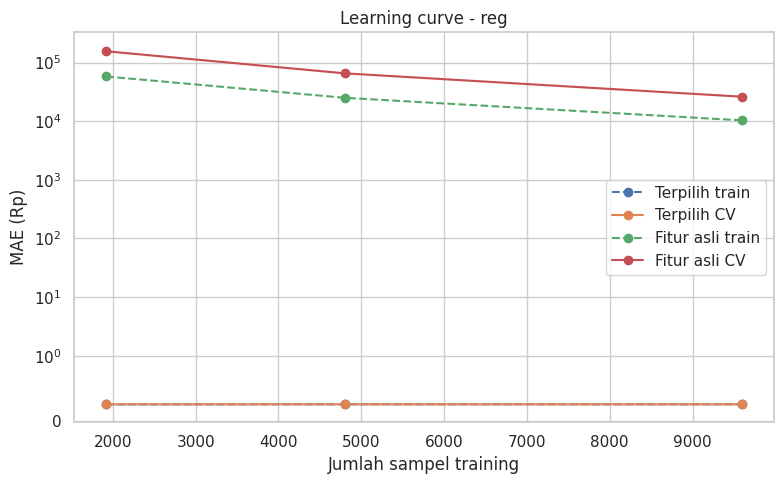

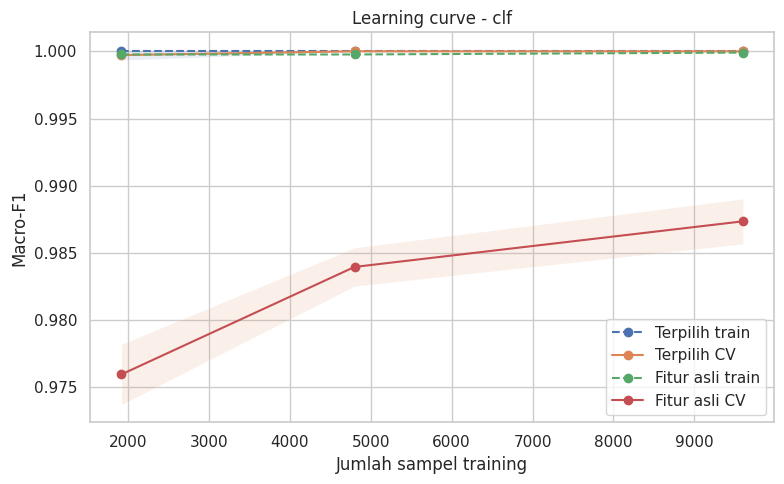

In [ ]:
for task in ('reg','clf'):
    fig,ax=plt.subplots(figsize=(8,5))
    candidates=[('Terpilih',selected[task])]
    if selected[task]['scenario']!=raw_selected[task]['scenario'] or selected[task]['model']!=raw_selected[task]['model']:
        candidates.append(('Fitur asli',raw_selected[task]))
    for tag,row in candidates:
        model=fitted[(task,row['model'],row['scenario'])]
        X=make_features(search,task,row['feature_set']); y=search[target[task]]
        sizes,tr,va=learning_curve(model,X,y,cv=cv[task],train_sizes=[.2,.5,1.0],
                                   scoring=scoring[task]['main'],n_jobs=N_JOBS,shuffle=True,random_state=SEED,error_score='raise')
        sign=-1 if task=='reg' else 1
        ax.plot(sizes,sign*tr.mean(axis=1),'o--',label=tag+' train')
        ax.plot(sizes,sign*va.mean(axis=1),'o-',label=tag+' CV')
        ax.fill_between(sizes,sign*va.mean(axis=1)-va.std(axis=1),sign*va.mean(axis=1)+va.std(axis=1),alpha=.12)
    ax.set(xlabel='Jumlah sampel training',ylabel='MAE (Rp)' if task=='reg' else 'Macro-F1',title='Learning curve - '+task)
    if task=='reg': ax.set_yscale('symlog',linthresh=1)
    ax.legend(); showfig('09_learning_curve_'+task)

## 11. Stress test generalisasi dan sensitivitas outlier
Dilakukan pada development, dengan model dan parameter sudah dipilih. Group split menahan harga mobil tertentu agar tidak muncul pada training; temporal split melatih transaksi lebih awal dan menguji transaksi lebih akhir. Ini diagnosis tambahan, bukan test eksternal. Untuk outlier penghasilan, batas IQR dihitung hanya pada subset fit; bandingkan model dengan dan tanpa outlier pada validation yang sama, termasuk subgroup ekstrem. Tidak ada perubahan otomatis terhadap dataset utama.

In [ ]:
def metrics(task,y,p):
    if task=='reg':
        return {'MAE':mean_absolute_error(y,p),'RMSE':np.sqrt(mean_squared_error(y,p)),
                'R2':r2_score(y,p),'MedianAE':median_absolute_error(y,p),
                'MAPE_pct':np.mean(np.abs((np.asarray(y)-p)/np.asarray(y)))*100,
                'MaxAE':np.max(np.abs(np.asarray(y)-p))}
    return {'Accuracy':accuracy_score(y,p),'Balanced_accuracy':balanced_accuracy_score(y,p),
            'Precision':precision_score(y,p,zero_division=0),'Recall':recall_score(y,p,zero_division=0),
            'F1':f1_score(y,p,zero_division=0),'Macro_F1':f1_score(y,p,average='macro',zero_division=0)}

def candidate_predict(task,row,tr,va):
    estimator=clone(fitted[(task,row['model'],row['scenario'])])
    estimator.fit(make_features(tr,task,row['feature_set']),tr[target[task]])
    return estimator.predict(make_features(va,task,row['feature_set']))

gtr,gva=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED).split(dev,groups=dev.price_idr))
cutoff=dev.date.quantile(.8)
splits={'Unseen price':(dev.iloc[gtr],dev.iloc[gva]),'Temporal':(dev.loc[dev.date<cutoff],dev.loc[dev.date>=cutoff])}
assert set(splits['Unseen price'][0].price_idr).isdisjoint(splits['Unseen price'][1].price_idr)
print('Harga ditahan:',sorted(splits['Unseen price'][1].price_idr.unique()),'| Cutoff temporal:',cutoff)
stress=[]
for split,(tr,va) in splits.items():
    for task in ('reg','clf'):
        for name,row in [('Selected ML',selected[task]),('Best raw ML',raw_selected[task])]:
            p=candidate_predict(task,row,tr,va)
            stress.append({'split':split,'task':task,'method':name,'model':row['model'],'n_train':len(tr),'n_eval':len(va),**metrics(task,va[target[task]],p)})
        p=formula_installment(va) if task=='reg' else formula_status(va)
        stress.append({'split':split,'task':task,'method':'Formula/rule','model':'Non-ML','n_train':0,'n_eval':len(va),**metrics(task,va[target[task]],p)})
stress_df=pd.DataFrame(stress); display(stress_df); stress_df.to_csv(OUT/'generalization_stress.csv',index=False)

Harga ditahan: [np.int64(210000000), np.int64(290000000), np.int64(390000000), np.int64(430000000), np.int64(520000000), np.int64(550000000)] | Cutoff temporal: 2026-01-23 00:00:00


,split,task,method,model,n_train,n_eval,MAE,RMSE,R2,MedianAE,MAPE_pct,MaxAE,Accuracy,Balanced_accuracy,Precision,Recall,F1,Macro_F1
0,Unseen price,reg,Selected ML,Linear Regression,46834,13182,0.2499,0.2880,1.0000,0.2519,0.0000,0.4989,NaN,NaN,NaN,NaN,NaN,NaN
1,Unseen price,reg,Best raw ML,Random Forest,46834,13182,"886,044.2090","1,281,641.7197",0.9757,"555,268.5750",7.2289,"4,200,077.3000",NaN,NaN,NaN,NaN,NaN,NaN
2,Unseen price,reg,Formula/rule,Non-ML,0,13182,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN
3,Unseen price,clf,Selected ML,Decision Tree,46834,13182,NaN,NaN,NaN,NaN,NaN,NaN,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
4,Unseen price,clf,Best raw ML,XGBoost,46834,13182,NaN,NaN,NaN,NaN,NaN,NaN,0.9793,0.9853,0.9339,0.9997,0.9657,0.9754
5,Unseen price,clf,Formula/rule,Non-ML,0,13182,NaN,NaN,NaN,NaN,NaN,NaN,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
6,Temporal,reg,Selected ML,Linear Regression,47997,12019,0.2517,0.2900,1.0000,0.2578,0.0000,0.5032,NaN,NaN,NaN,NaN,NaN,NaN
7,Temporal,reg,Best raw ML,Random Forest,47997,12019,"3,707.8191","8,122.6610",1.0000,"1,551.9000",0.0334,"144,354.1875",NaN,NaN,NaN,NaN,NaN,NaN
8,Temporal,reg,Formula/rule,Non-ML,0,12019,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN
9,Temporal,clf,Selected ML,Decision Tree,47997,12019,NaN,NaN,NaN,NaN,NaN,NaN,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


In [ ]:
itr,iva=train_test_split(dev.index,test_size=.2,random_state=SEED,stratify=dev.affordability_status)
tr,va=dev.loc[itr],dev.loc[iva]
a,b=tr.monthly_income.quantile([.25,.75]); lo,hi=a-1.5*(b-a),b+1.5*(b-a)
keep=tr.monthly_income.between(lo,hi); extreme=~va.monthly_income.between(lo,hi)
sensitivity=[]
for tag,fit_data in [('All valid',tr),('Exclude income IQR flags',tr.loc[keep])]:
    p=candidate_predict('clf',selected['clf'],fit_data,va)
    for subset,mask in [('All validation',np.ones(len(va),dtype=bool)),('Income IQR flags',extreme.to_numpy()),('Other income',~extreme.to_numpy())]:
        if mask.sum(): sensitivity.append({'training':tag,'subset':subset,'n_train':len(fit_data),'n_eval':int(mask.sum()),**metrics('clf',va.affordability_status.to_numpy()[mask],p[mask])})
sensitivity_df=pd.DataFrame(sensitivity); display(sensitivity_df); sensitivity_df.to_csv(OUT/'outlier_sensitivity.csv',index=False)
print('Dataset utama tetap mempertahankan seluruh nilai valid.')

,training,subset,n_train,n_eval,Accuracy,Balanced_accuracy,Precision,Recall,F1,Macro_F1
0,All valid,All validation,48012,12004,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,All valid,Income IQR flags,48012,1118,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
2,All valid,Other income,48012,10886,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
3,Exclude income IQR flags,All validation,43633,12004,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
4,Exclude income IQR flags,Income IQR flags,43633,1118,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
5,Exclude income IQR flags,Other income,43633,10886,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


Dataset utama tetap mempertahankan seluruh nilai valid.


## 12. Final training dan evaluasi holdout
Kandidat terpilih dilatih pada seluruh development set (tidak hanya sampel tuning). Model terbaik tidak diganti berdasarkan hasil final test. Evaluasi best raw ML dilakukan sebagai pembanding yang sudah ditetapkan sebelum final test. Baseline formula dan dummy ditampilkan untuk transparansi. Tidak ada klaim persetujuan bank atau risiko gagal bayar.

In [ ]:
final_models={}; final_predictions={}; final_records=[]
for task in ('reg','clf'):
    y=test[target[task]]
    for label,row in [('Selected ML',selected[task]),('Best raw ML',raw_selected[task])]:
        estimator=clone(fitted[(task,row['model'],row['scenario'])])
        estimator.fit(make_features(dev,task,row['feature_set']),dev[target[task]])
        p=estimator.predict(make_features(test,task,row['feature_set']))
        final_records.append({'task':task,'method':label,'model':row['model'],'scenario':row['scenario'],**metrics(task,y,p)})
        if label=='Selected ML':
            final_models[task]=estimator; final_predictions[task]=p
    dummy=DummyRegressor(strategy='median') if task=='reg' else DummyClassifier(strategy='most_frequent')
    dummy.fit(make_features(dev,task,'raw'),dev[target[task]])
    p=dummy.predict(make_features(test,task,'raw'))
    final_records.append({'task':task,'method':'Dummy','model':'Dummy','scenario':'baseline',**metrics(task,y,p)})
    p=formula_installment(test) if task=='reg' else formula_status(test)
    final_records.append({'task':task,'method':'Formula/rule','model':'Non-ML','scenario':'baseline',**metrics(task,y,p)})
final_metrics=pd.DataFrame(final_records)
for task,name in [('reg','regression_metrics'),('clf','classification_metrics')]:
    result=final_metrics.query('task == @task').dropna(axis=1,how='all'); display(result)
    result.to_csv(OUT/(name+'.csv'),index=False)
print('Final holdout:',len(test))

,task,method,model,scenario,MAE,RMSE,R2,MedianAE,MAPE_pct,MaxAE
0,reg,Selected ML,Linear Regression,3_financial_tuned,0.2510,0.2899,1.0000,0.2585,0.0000,0.5018
1,reg,Best raw ML,Random Forest,1_raw_baseline,"3,020.2984","6,953.6775",1.0000,"1,213.6438",0.0266,"161,044.0250"
2,reg,Dummy,Dummy,baseline,"6,005,757.8081","9,652,923.5013",-0.1114,"3,614,252.0000",60.4533,"56,476,755.0000"
3,reg,Formula/rule,Non-ML,baseline,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000


,task,method,model,scenario,Accuracy,Balanced_accuracy,Precision,Recall,F1,Macro_F1
4,clf,Selected ML,Decision Tree,3_financial_tuned,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
5,clf,Best raw ML,XGBoost,2_raw_tuned,0.9943,0.9937,0.9912,0.9918,0.9915,0.9936
6,clf,Dummy,Dummy,baseline,0.6665,0.5000,0.0000,0.0000,0.0000,0.3999
7,clf,Formula/rule,Non-ML,baseline,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


Final holdout: 15004


## 13. Visualisasi hasil regresi dan klasifikasi
Residual, actual vs predicted, error per tenor dan harga, confusion matrix, ROC/PR curve, serta kesalahan dekat batas rasio 35%. Probabilitas classifier mengacu pada label sintetis, bukan peluang pengajuan diterima.

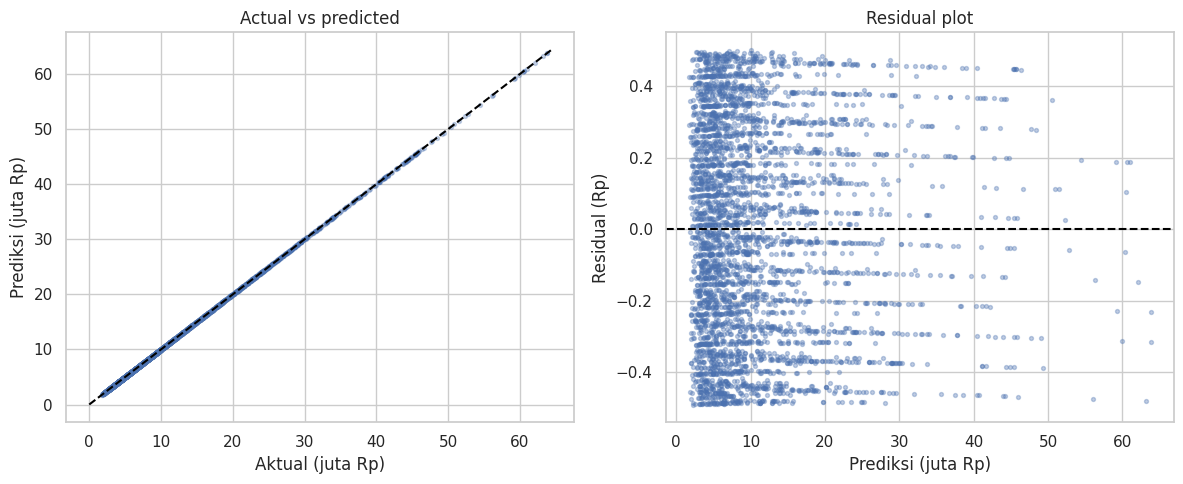

,n,MAE,max_error
loan_tenure,,,
12,3022,0.2516,0.4823
24,3036,0.2519,0.4880
36,2969,0.2492,0.4897
48,3006,0.2506,0.4953
60,2971,0.2519,0.5018


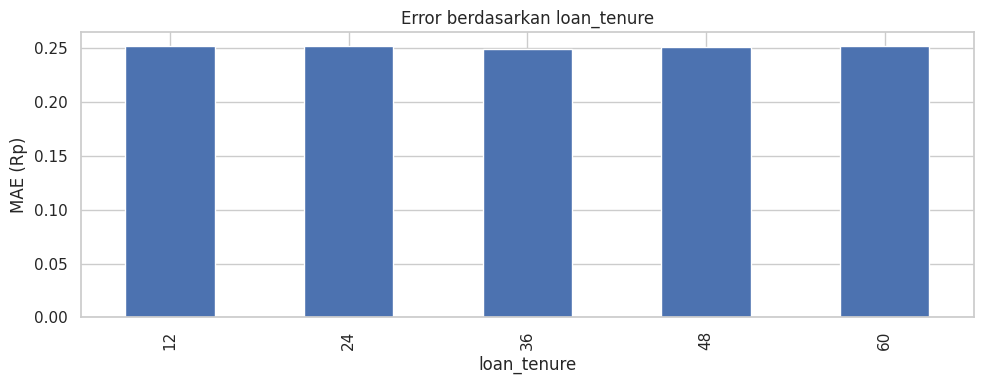

,n,MAE,max_error
price_idr,,,
170000000,383,0.2609,0.4922
180000000,489,0.2555,0.4918
190000000,337,0.2489,0.4922
210000000,326,0.2411,0.4967
220000000,325,0.2479,0.4954
250000000,960,0.2501,0.4962
260000000,413,0.2531,0.4938
280000000,849,0.2461,0.4959
290000000,317,0.2464,0.4954


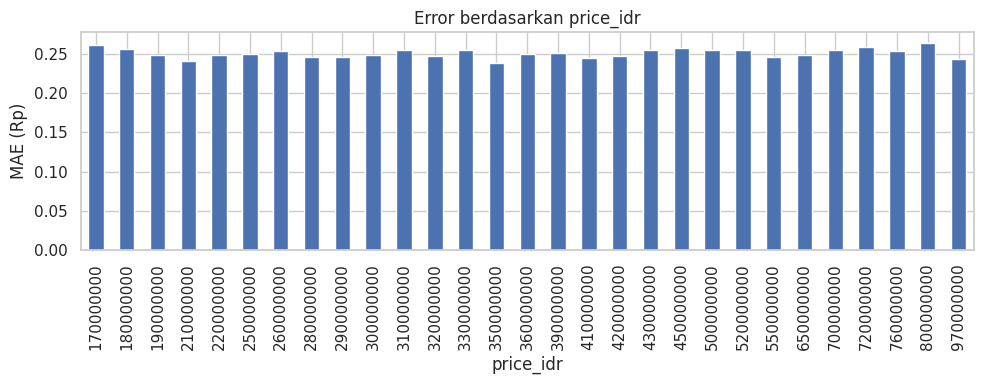

In [ ]:
reg_eval=test[['price_idr','loan_tenure','monthly_installment','dti_ratio']].copy()
reg_eval['prediction']=final_predictions['reg']; reg_eval['residual']=reg_eval.monthly_installment-reg_eval.prediction
reg_eval['abs_error']=reg_eval.residual.abs()
sample=reg_eval.sample(min(4000,len(reg_eval)),random_state=SEED)
fig,ax=plt.subplots(1,2,figsize=(12,5))
ax[0].scatter(sample.monthly_installment/1e6,sample.prediction/1e6,s=8,alpha=.3)
mx=reg_eval.monthly_installment.max()/1e6; ax[0].plot([0,mx],[0,mx],'--',color='black'); ax[0].set(xlabel='Aktual (juta Rp)',ylabel='Prediksi (juta Rp)',title='Actual vs predicted')
ax[1].scatter(sample.prediction/1e6,sample.residual,s=8,alpha=.35); ax[1].axhline(0,color='black',ls='--'); ax[1].set(xlabel='Prediksi (juta Rp)',ylabel='Residual (Rp)',title='Residual plot')
showfig('10_regression_diagnostics')
for c in ['loan_tenure','price_idr']:
    t=reg_eval.groupby(c).agg(n=('abs_error','size'),MAE=('abs_error','mean'),max_error=('abs_error','max'))
    display(t); t.to_csv(OUT/('error_by_'+c+'.csv'))
    t.MAE.plot.bar(figsize=(10,4)); plt.ylabel('MAE (Rp)'); plt.title('Error berdasarkan '+c); showfig('11_error_'+c)

ROC-AUC: 1.0 | Average precision: 1.0


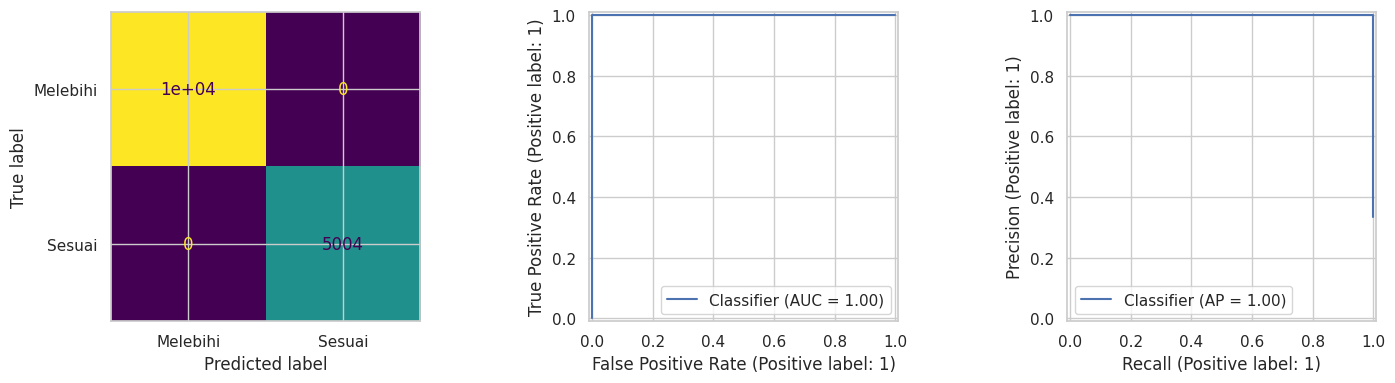

,margin_pct_points,n,accuracy,errors,formula_accuracy
0,0.5000,131,1.0000,0,1.0000
1,1.0000,272,1.0000,0,1.0000
2,2.0000,534,1.0000,0,1.0000
3,5.0000,1259,1.0000,0,1.0000


False positive (diprediksi sesuai padahal melebihi): 0
False negative: 0


In [ ]:
y=test.affordability_status; p=final_predictions['clf']
prob=final_models['clf'].predict_proba(make_features(test,'clf',selected['clf']['feature_set']))[:,1]
print('ROC-AUC:',roc_auc_score(y,prob),'| Average precision:',average_precision_score(y,prob))
fig,ax=plt.subplots(1,3,figsize=(15,4))
ConfusionMatrixDisplay.from_predictions(y,p,display_labels=['Melebihi','Sesuai'],ax=ax[0],colorbar=False)
RocCurveDisplay.from_predictions(y,prob,ax=ax[1]); PrecisionRecallDisplay.from_predictions(y,prob,ax=ax[2]); showfig('12_classification_diagnostics')
near=[]
for width in [0.5,1,2,5]:
    mask=test.dti_ratio.sub(35).abs().le(width).to_numpy()
    if mask.sum():
        near.append({'margin_pct_points':width,'n':int(mask.sum()),'accuracy':accuracy_score(y.to_numpy()[mask],p[mask]),
                     'errors':int((y.to_numpy()[mask]!=p[mask]).sum()),'formula_accuracy':accuracy_score(y.to_numpy()[mask],formula_status(test)[mask])})
near_df=pd.DataFrame(near); display(near_df); near_df.to_csv(OUT/'near_threshold.csv',index=False)
print('False positive (diprediksi sesuai padahal melebihi):',confusion_matrix(y,p,labels=[0,1])[0,1])
print('False negative:',confusion_matrix(y,p,labels=[0,1])[1,0])

## 14. Interpretasi model dan uji konsistensi finansial
Feature importance model tree atau koefisien model linear dapat membantu interpretasi, tetapi fitur turunan saling berkaitan sehingga tidak menunjukkan hubungan kausal. Uji DP/tenor dan kesesuaian keputusan dijalankan pada kombinasi katalog; formula menjadi keputusan konsisten pada aplikasi berikutnya. Tidak menggabungkan classifier dan rule dengan `AND` untuk menyembunyikan konflik.

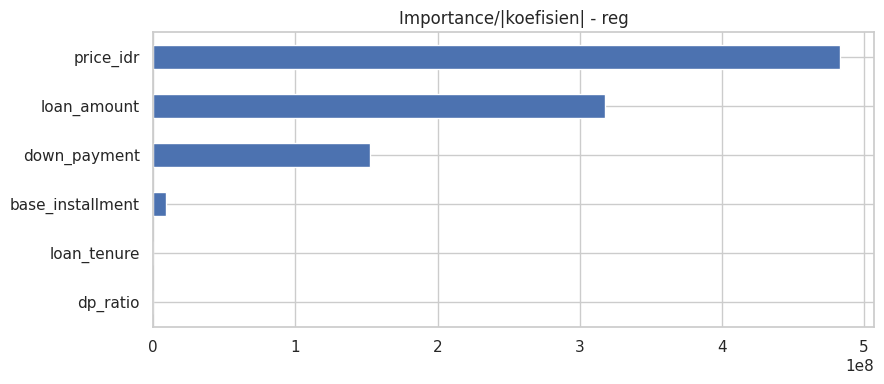

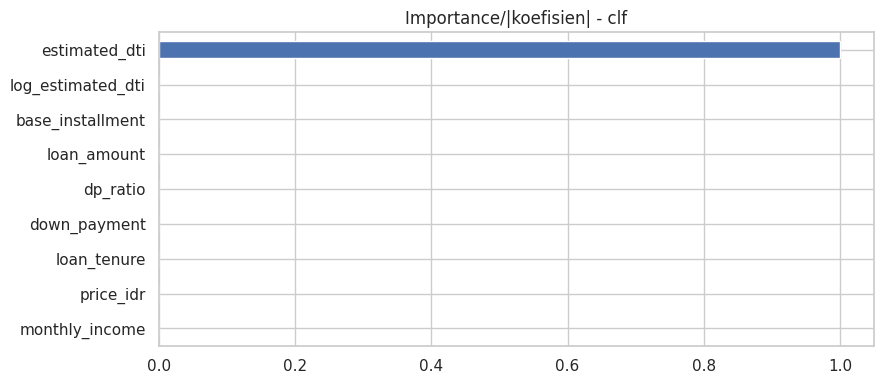

,dp_increase_violations,tenure_increase_violations,disagreement_with_ml_ratio,disagreement_with_formula_rule,n
ml_installment,0.0000,0.0000,NaN,NaN,NaN
formula_installment,0.0000,0.0000,NaN,NaN,NaN
classifier,NaN,NaN,15.0000,15.0000,"3,450.0000"


316

In [ ]:
for task in ('reg','clf'):
    est=final_models[task]; m=est.named_steps['model']; feature_names=list(make_features(dev.head(1),task,selected[task]['feature_set']).columns)
    if 'poly' in est.named_steps:
        feature_names=est.named_steps['poly'].get_feature_names_out(feature_names)
    if hasattr(m,'feature_importances_'): vals=m.feature_importances_
    elif hasattr(m,'coef_'): vals=np.abs(np.asarray(m.coef_).reshape(-1))
    else: continue
    pd.Series(vals,index=feature_names).nlargest(12).sort_values().plot.barh(figsize=(9,4)); plt.title('Importance/|koefisien| - '+task); showfig('13_importance_'+task)

catalog=(df[['company','model','body_style','price_idr']].drop_duplicates()
         .sort_values(['price_idr','company','model']).reset_index(drop=True))
assert not catalog.duplicated(['company','model']).any(), 'Katalog memiliki beberapa varian/harga; perlu ID varian.'
scenarios=pd.DataFrame([(r.company,r.model,r.price_idr,d,t,int(r.price_idr*d/100),income)
    for r in catalog.itertuples(index=False) for d in [20,25,30,35,40] for t in [12,24,36,48,60]
    for income in [5_000_000,15_000_000,30_000_000]],columns=['company','model','price_idr','dp_pct','loan_tenure','down_payment','monthly_income'])
scenarios['ml_installment']=final_models['reg'].predict(make_features(scenarios,'reg',selected['reg']['feature_set']))
scenarios['ml_status']=final_models['clf'].predict(make_features(scenarios,'clf',selected['clf']['feature_set']))
scenarios['formula_installment']=formula_installment(scenarios); scenarios['rule_status']=formula_status(scenarios)
scenarios['ml_ratio_status']=(scenarios.ml_installment<=THRESHOLD*scenarios.monthly_income).astype(int)
checks={}
for c in ['ml_installment','formula_installment']:
    dp_diff=scenarios.sort_values('dp_pct').groupby(['company','model','loan_tenure','monthly_income'])[c].diff()
    tenure_diff=scenarios.sort_values('loan_tenure').groupby(['company','model','dp_pct','monthly_income'])[c].diff()
    checks[c]={'dp_increase_violations':int(dp_diff.gt(1e-6).sum()),'tenure_increase_violations':int(tenure_diff.gt(1e-6).sum())}
checks['classifier']={'disagreement_with_ml_ratio':int((scenarios.ml_status!=scenarios.ml_ratio_status).sum()),
                      'disagreement_with_formula_rule':int((scenarios.ml_status!=scenarios.rule_status).sum()),'n':len(scenarios)}
display(pd.DataFrame(checks).T)
assert checks['formula_installment']['dp_increase_violations']==checks['formula_installment']['tenure_increase_violations']==0
scenarios.to_csv(OUT/'catalog_stress_test.csv',index=False)
(OUT/'financial_consistency.json').write_text(json.dumps(checks,indent=2))

## 15. Ekspor model terpilih, katalog dan metadata deployment
Model disimpan sebagai pipeline sklearn/XGBoost tanpa transformer custom yang sulit di-unpickle. Modul `features.py` yang dihasilkan menjadi kontrak preprocessing bersama notebook dan aplikasi. Fitur input mentah sama dengan aplikasi awal, tetapi model mungkin memerlukan fitur turunan; **jangan hanya mengganti file PKL pada app.py lama**. Aplikasi harus memanggil `make_features` dengan `feature_set` di metadata. Model diekspor dari training development yang telah dievaluasi (tidak dilatih ulang dengan test). File requirements mengunci versi training dan inferensi; versi Streamlit perlu ditentukan saat revisi repo.

In [ ]:
(OUT/'features.py').write_text(FEATURE_SOURCE,encoding='utf-8')
catalog.to_csv(OUT/'katalog_mobil.csv',index=False)
metadata={'seed':SEED,'threshold':THRESHOLD,'target_definition':'Observed installment / (annual income / 12) <= 0.35, unrounded',
          'dataset_sha256':source_hash,'n_credit_valid':len(df),'n_development':len(dev),'n_cv_sample':len(search),
          'n_test':len(test),'cv_folds':N_FOLDS,'search_iterations':N_ITER,'python':platform.python_version(),'versions':versions,
          'limitations':['Deterministic interest-free target in supplied data','Affordability rule, not actual credit approval','No external validation'],
          'recommended_app_decision':'formula_status; ML results displayed separately', 'models':{}}
for task,filename in [('reg','model_cicilan.pkl'),('clf','model_kelayakan.pkl')]:
    model=final_models[task]; row=selected[task]
    joblib.dump(model,OUT/filename,compress=3)
    loaded=joblib.load(OUT/filename)
    inputs=make_features(test.head(20),task,row['feature_set'])
    np.testing.assert_allclose(loaded.predict(inputs),model.predict(inputs))
    raw_cols=RAW_REG if task=='reg' else RAW_CLF
    meta_metrics=final_metrics.query('task == @task and method == "Selected ML"').iloc[0].dropna().to_dict()
    metadata['models'][task]={'file':filename,'name':row['model'],'scenario':row['scenario'],'feature_set':row['feature_set'],
        'feature_columns':inputs.columns.tolist(),'raw_input_columns':raw_cols,'cv_primary':row['cv_primary'],'cv_std':row['cv_std'],
        'cv_metric':'MAE' if task=='reg' else 'Macro-F1','params':model.get_params(deep=True),'test_metrics':meta_metrics,
        'training_ranges':{c:{'min':float(dev[c].min()),'max':float(dev[c].max())} for c in raw_cols},
        'size_bytes':(OUT/filename).stat().st_size}
    print(filename, row['model'],round((OUT/filename).stat().st_size/1024**2,2),'MB')
(OUT/'model_metadata.json').write_text(json.dumps(metadata,indent=2,default=str),encoding='utf-8')
(OUT/'requirements-model.txt').write_text('\n'.join(f'{k}=={v}' for k,v in versions.items() if k in ['numpy','pandas','scikit-learn','xgboost','joblib'])+'\n')
example=pd.DataFrame([{'price_idr':300_000_000,'down_payment':75_000_000,'loan_tenure':48,'monthly_income':15_000_000}])
for task in ('reg','clf'):
    row=metadata['models'][task]
    loaded=joblib.load(OUT/row['file'])
    print(task,row['name'],loaded.predict(make_features(example,task,row['feature_set']))[0])
print('Formula:',formula_installment(example)[0],'| Rule:',formula_status(example)[0])
print('Output folder:',OUT.resolve())

model_cicilan.pkl Linear Regression 0.0 MB
model_kelayakan.pkl Decision Tree 0.0 MB
reg Linear Regression 4687499.508413703
clf Decision Tree 1
Formula: 4687500.0 | Rule: 1
Output folder: /content/outputs_car_financing


## 16. Kesimpulan otomatis dan batas penelitian
Hasil aktual dihitung dari eksekusi, bukan angka yang ditulis manual. Model ML terpilih digunakan sebagai hasil eksperimen; perhitungan formula menjadi referensi dan aturan kemampuan bayar konsisten. Jika ingin memodelkan bunga aktual, persetujuan kredit atau gagal bayar, dibutuhkan target dan data tambahan. Simulasi bunga dan kewajiban lain dapat dibangun pada aplikasi dengan asumsi yang dinyatakan terpisah dari model dataset.

In [ ]:
for task in ('reg','clf'):
    row=metadata['models'][task]
    m=row['test_metrics']; print(f"{task.upper()}: {row['name']} | {row['scenario']} | CV {row['cv_metric']} = {row['cv_primary']:.6f}")
    print('Final test:',{k:round(v,6) for k,v in m.items() if isinstance(v,(int,float,np.number))})
print('Cocok formula:',int(df.formula_error.eq(0).sum()),'/',len(df))
print('Status berdasarkan rasio 35% bukan persetujuan kredit.')
print('File siap untuk tahap revisi repo: model cicilan, model kelayakan, katalog, metadata, features.py, requirements-model.txt.')

REG: Linear Regression | 3_financial_tuned | CV MAE = 0.253273
Final test: {'MAE': 0.251039, 'RMSE': 0.289918, 'R2': 1.0, 'MedianAE': 0.258529, 'MAPE_pct': 4e-06, 'MaxAE': 0.501801}
CLF: Decision Tree | 3_financial_tuned | CV Macro-F1 = 1.000000
Final test: {'Accuracy': 1.0, 'Balanced_accuracy': 1.0, 'Precision': 1.0, 'Recall': 1.0, 'F1': 1.0, 'Macro_F1': 1.0}
Cocok formula: 75020 / 75020
Status berdasarkan rasio 35% bukan persetujuan kredit.
File siap untuk tahap revisi repo: model cicilan, model kelayakan, katalog, metadata, features.py, requirements-model.txt.
